# Monte Carlo Averaging from pre-calculated coupling efficiency maps

In [1]:
from matplotlib import pyplot as plt
import numpy as np
from scipy.special import jv, kv
from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate

In [2]:
import os
from joblib import cpu_count
import glob

In [3]:
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0

In [4]:
import sys
from pathlib import Path
import joblib
import time

src_path = Path("/Users/tliu/oh_suppression/codes/src")

if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from oh_suppression.coupling import *

In [5]:
from oh_suppression.point_source_coupling import *
from oh_suppression.flat_background_coupling import *
from oh_suppression.extended_source_coupling import *

In [6]:
from matplotlib import pyplot as plt
import numpy as np
from scipy import special #import jv, kv
# from scipy.special import j1 # Bessel function of the first kind of order 1, for the diffraction pattern calculation
from scipy.optimize import root_scalar
from scipy.constants import c, epsilon_0, mu_0, pi
import scipy.integrate as integrate
# jn_zeros is a function that returns the zeros of the Bessel function of the first kind, 
# which are needed to find the roots for the LP01 mode in a step-index fibre
from scipy.special import jn_zeros  # NEW: needed to get the first zero of J0
from scipy.optimize import brentq
from scipy.optimize import fminbound
from dataclasses import dataclass
import pandas as pd
from joblib import Parallel, delayed
import os

In [7]:
import astropy.units as u
from astropy.modeling.models import Moffat1D
# Source: https://docs.astropy.org/en/stable/api/astropy.modeling.functional_models.Moffat1D.html
from astropy.modeling.functional_models import Moffat2D
# Source: https://docs.astropy.org/en/stable/api/astropy.modeling.functional_models.Moffat2D.html


In [8]:
from scipy.interpolate import RegularGridInterpolator
from scipy.interpolate import PchipInterpolator
from tqdm.auto import tqdm
import math

In [9]:
from oh_suppression.point_source_coupling import *
from oh_suppression.flat_background_coupling import *
from oh_suppression.point_source_coupling import *
from oh_suppression.image_plane_fields import *
from oh_suppression.fibre_modes import *
from oh_suppression.coupling_maps_2d import *

In [10]:
def choose_bin_decentre_resolution(
        bin_id,
        mode_count_table,
        core_radius_array,
        NA,
        lam0,
        x_1d,
        n_fixed=51
):
    """
    Choose one decentre-quadrant resolution for a whole V-bin.

    Bin 0:
        Return None because LP01 can use the
        radially symmetric method.

    Bins 1-2:
        Use a fixed 51 x 51 positive quadrant,
        producing a 101 x 101 full map.

    Bin 3 onward:
        Choose the full-map resolution so that its physical
        pixel spacing is no coarser than the original 2D
        field-grid spacing.

        The full map is always forced to have an odd number
        of pixels so that (0, 0) is exactly the central pixel.
    """

    # ---------------------------------------------------------
    # Bin 0: radial method
    # ---------------------------------------------------------

    if bin_id == 0:
        return None

    # ---------------------------------------------------------
    # Bins 1-2: fixed moderate resolution
    # ---------------------------------------------------------

    if bin_id in [1, 2]:
        return n_fixed

    # ---------------------------------------------------------
    # Find radii belonging to this V-bin
    # ---------------------------------------------------------

    V_array = (
        2 * np.pi
        * core_radius_array
        * NA
        / lam0
    )

    row = mode_count_table.loc[
        mode_count_table["file"] == bin_id
    ].iloc[0]

    V_min = row["V_min"]
    V_max = row["V_max"]

    mask = (
        (V_array >= V_min)
        & (V_array < V_max)
    )

    selected_radii = core_radius_array[mask]

    if len(selected_radii) == 0:
        return None

    # Largest radius actually calculated in this bin
    a_max = selected_radii.max()

    # ---------------------------------------------------------
    # Original electric-field grid spacing
    # ---------------------------------------------------------

    field_spacing = np.abs(
        x_1d[1] - x_1d[0]
    )

    # ---------------------------------------------------------
    # Required FULL map size
    #
    # Full map runs from -a_max to +a_max,
    # so physical width = 2*a_max.
    # ---------------------------------------------------------

    n_full = (
        int(
            np.ceil(
                2 * a_max / field_spacing
            )
        )
        + 1
    )

    # Full map must be odd so that zero is a sampled
    # central pixel.
    if n_full % 2 == 0:
        n_full += 1

    # ---------------------------------------------------------
    # Convert full map size back to quadrant size
    #
    # n_full = 2*n_quadrant - 1
    # ---------------------------------------------------------

    n_quadrant = (
        n_full + 1
    ) // 2

    return n_quadrant

In [11]:
data_dir = "/Users/tliu/oh_suppression/data/simulated_coupling_maps/coupling_results_NA0p1"

In [12]:
filepaths = sorted(
    glob.glob(
        os.path.join(
            data_dir,
            "coupling_maps_bin_*.joblib"
        )
    )
)

print(f"Found {len(filepaths)} files")

Found 19 files


In [13]:
# Note bin 14 is empty because the range of V_c is too small to contain any a values
all_results = []

for filepath in filepaths:

    loaded = joblib.load(filepath)

    print(
        os.path.basename(filepath),
        "->",
        len(loaded["results"]),
        "radii"
    )

    all_results.extend(
        loaded["results"]
    )

coupling_maps_bin_00_V_0.0000_to_2.4048.joblib -> 33 radii
coupling_maps_bin_01_V_2.4048_to_3.8317.joblib -> 34 radii
coupling_maps_bin_02_V_3.8317_to_5.1356.joblib -> 31 radii
coupling_maps_bin_03_V_5.1356_to_5.5201.joblib -> 9 radii
coupling_maps_bin_04_V_5.5201_to_6.3802.joblib -> 21 radii
coupling_maps_bin_05_V_6.3802_to_7.0156.joblib -> 15 radii
coupling_maps_bin_06_V_7.0156_to_7.5883.joblib -> 14 radii
coupling_maps_bin_07_V_7.5883_to_8.4172.joblib -> 19 radii
coupling_maps_bin_08_V_8.4172_to_8.6537.joblib -> 6 radii
coupling_maps_bin_09_V_8.6537_to_8.7715.joblib -> 3 radii
coupling_maps_bin_10_V_8.7715_to_9.7610.joblib -> 24 radii
coupling_maps_bin_11_V_9.7610_to_9.9361.joblib -> 4 radii
coupling_maps_bin_12_V_9.9361_to_10.1735.joblib -> 5 radii
coupling_maps_bin_13_V_10.1735_to_11.0647.joblib -> 22 radii
coupling_maps_bin_15_V_11.0864_to_11.6198.joblib -> 13 radii
coupling_maps_bin_16_V_11.6198_to_11.7915.joblib -> 4 radii
coupling_maps_bin_17_V_11.7915_to_12.2251.joblib -> 10 

In [14]:
all_results = sorted(
    all_results,
    key=lambda result: result["a"]
)

In [15]:
for result in all_results[:10]:

    print(
        f"a = {result['a'] * 1e6:.2f} µm | "
        f"V = {result['V']:.3f} | "
        f"map = {result['eta_total_map'].shape}"
    )

a = 2.50 µm | V = 1.047 | map = (101, 101)
a = 2.60 µm | V = 1.089 | map = (101, 101)
a = 2.70 µm | V = 1.131 | map = (101, 101)
a = 2.80 µm | V = 1.173 | map = (101, 101)
a = 2.90 µm | V = 1.215 | map = (101, 101)
a = 3.00 µm | V = 1.257 | map = (101, 101)
a = 3.10 µm | V = 1.299 | map = (101, 101)
a = 3.20 µm | V = 1.340 | map = (101, 101)
a = 3.30 µm | V = 1.382 | map = (101, 101)
a = 3.40 µm | V = 1.424 | map = (101, 101)


In [16]:
summary_rows = []

for result in all_results:

    summary_rows.append({
        "a_um":
            result["a"] * 1e6,

        "V":
            result["V"],

        "nx":
            len(result["decentre_x_1d"]),

        "ny":
            len(result["decentre_y_1d"]),

        "dx_um":
            np.diff(
                result["decentre_x_1d"]
            ).mean() * 1e6,

        "dy_um":
            np.diff(
                result["decentre_y_1d"]
            ).mean() * 1e6,

        "n_modes":
            len(
                result["mode_eta_maps"]
            ),
    })

summary_table = pd.DataFrame(
    summary_rows
)

summary_table

,a_um,V,nx,ny,dx_um,dy_um,n_modes
0,2.5,1.047198,101,101,0.050000,0.050000,1
1,2.6,1.089085,101,101,0.052000,0.052000,1
2,2.7,1.130973,101,101,0.054000,0.054000,1
3,2.8,1.172861,101,101,0.056000,0.056000,1
4,2.9,1.214749,101,101,0.058000,0.058000,1
...,...,...,...,...,...,...,...
271,29.6,12.398819,241,241,0.246667,0.246667,42
272,29.7,12.440707,241,241,0.247500,0.247500,42
273,29.8,12.482595,241,241,0.248333,0.248333,42
274,29.9,12.524483,241,241,0.249167,0.249167,42


In [17]:
def sigma_jitter_milliarcsec_to_metres(sigma_jitter_rms, focal_length, demagnification): 
    """
    Convert the RMS jitter from milliarcseconds to metres at the fibre plane.

    Parameters: 
    sigma_jitter_rms : float
        RMS jitter in milliarcseconds.
    focal_length : float
        Focal length of the telescope in metres.
    demagnification : float 
        Demagnification factor from the telescope focal plane to the fibre plane, done by the reimaging optics. 

    Returns:
    float
        RMS jitter in metres at the fibre plane.
    """
    rad_to_arcsec = (180 / np.pi) * 3600 # essentially, 1 radian = 206264.80624709636 arcseconds

    # Convert jitter from milliarcseconds to radians
    sigma_theta_radians = sigma_jitter_rms * 1e-3 / rad_to_arcsec 

    # Convert jitter from radians to physical units (metres) at the fibre plane using the focal length and demagnification

    sigma_jitter_metres = demagnification * focal_length * sigma_theta_radians

    return sigma_jitter_metres

In [18]:
def generate_jitter_positions(
    sigma_jitter_rms_mas: float,
    focal_length: float,
    demagnification: float,
    n_samples: int,
    rng: np.random.Generator
) -> tuple[np.ndarray, np.ndarray]:
    """
    Generate random x and y tip-tilt jitter displacements at the fibre plane. 
    The displacements are drawn from a normal distribution with mean 0 and standard deviation corresponding to 
    the RMS jitter specified in milliarcseconds.
    This is a helper function to generate random jitter positions for Monte Carlo simulations of coupling efficiency.

    Parameters
    ----------
    sigma_jitter_rms_mas:
        RMS jitter in milliarcseconds.

    focal_length:
        Telescope focal length in metres.

    demagnification:
        Demagnification factor between the telescope focal plane
        and the fibre plane.

    n_samples:
        Number of random jitter positions.

    rng:
        NumPy random number generator.

    Returns
    -------
    delta_x, delta_y:
        Random x and y jitter displacements at the fibre plane, in metres.
    """

    # Convert RMS jitter from milliarcseconds to metres at the fibre plane.
    sigma_jitter_metres = sigma_jitter_milliarcsec_to_metres(
        sigma_jitter_rms_mas,
        focal_length,
        demagnification
    )

    # Generate random x jitter positions.
    delta_x = rng.normal(
        loc=0,
        scale=sigma_jitter_metres,
        size=n_samples
    )

    # Generate random y jitter positions.
    delta_y = rng.normal(
        loc=0,
        scale=sigma_jitter_metres,
        size=n_samples
    )

    return delta_x, delta_y

In [19]:
def Monte_Carlo_point_source_coupling(
    x, y, 
    x_1d, y_1d,
    delta_x, delta_y, 
    eta_map_fixed: np.ndarray,
    acceptance_radius=None,
    fibre_x=0.0,
    fibre_y=0.0,
):
    """
    Perform a Monte Carlo simulation to calculate the coupling efficiency
    of a point source in the presence of tip-tilt jitter.

    For each random jitter position, the point source position is evaluated
    on the fixed 2D coupling efficiency map.

    Parameters
    ----------
    x_1d : 1D array of x-coordinates at the fibre plane, in metres.

    y_1d : 1D array of y-coordinates at the fibre plane, in metres.

    delta_x : Random x-direction jitter displacements at the fibre plane, in metres.

    delta_y : Random y-direction jitter displacements at the fibre plane, in metres.

    eta_map_fixed : np.ndarray
        Fixed 2D point-source coupling efficiency map.

    acceptance_radius : float or None
        Radius of the circular acceptance region, in metres.

        If None, no additional circular acceptance boundary is applied.

        If a radius is given, coupling is set to zero when the point
        source is outside this radius.

    fibre_x : float
        Fixed x-position of the fibre centre, in metres.

    fibre_y : float
        Fixed y-position of the fibre centre, in metres.

    Returns
    -------
    eta_samples : np.ndarray
        Coupling efficiency for each Monte Carlo jitter position.
    """

    # Number of Monte Carlo samples determined by the number of jitter positions provided.
    n_samples = len(delta_x)

    # Create an empty array in which to store the coupling efficiency for each jitter position.
    eta_samples = np.zeros(n_samples)


    # Apply a circular acceptance boundary if one is specified.
    if acceptance_radius is not None:

        # Mask the 2D coupling efficiency map to only include points within the acceptance radius.
        acceptance_mask = (
            np.sqrt(
                (x - fibre_x)**2
                + (y - fibre_y)**2
            )
            <= acceptance_radius
        )
        
        eta_map_fixed = eta_map_fixed.copy() 
        eta_map_fixed[~acceptance_mask] = 0.0

        # # Calculate the radial position of each point source.
        # radial_displacement = np.sqrt(
        #     delta_x**2 + delta_y**2
        # )

    for i in range(n_samples):
        # Calculate the shifted position (in physical units) of th point source due to jitter.
        dx_metre = delta_x[i]
        dy_metre = delta_y[i]

        # Find the closest x-grid position to the jittered point source, x_1d - dx_metre is 1d array minus a scalar, 
        # so the result is a 1d array of the same length as x_1d. np.abs gives the absolute value of each element in that array, 
        # and np.argmin returns the index of the minimum value in that array. This index corresponds to the closest x-grid position 
        # to the jittered point source.
        x_index = np.argmin(np.abs(x_1d - dx_metre)) 

        # Find the closest y-grid position to the jittered point source
        y_index = np.argmin(np.abs(y_1d - dy_metre))

        # Evaluate the coupling efficiency at the shifted position.
        eta_samples[i] = eta_map_fixed[y_index, x_index]

    return eta_samples

In [20]:
# wavelength of beam in vacuum
lam0 = 1.5e-6 
# numerical aperture of fibre
NA = 0.1 

# # Calculate the normalised frequency (V-number) of the fibre
# V = 2 * pi * (a / lam0) * NA
# print(f"V-number of the fibre: {V:.2f}")

In [21]:
f_coude = 399
F_fibre = 1 / (2 * np.tan(np.arcsin(NA)))
Magnification = F_fibre / 49.9
F_focus = 49.9
D_M1 = 8.0
D_M1 = 8.0 # Diameter of the primary mirror in meters
D_obstruction = 1.0 # Diameter of the central obstruction in meters
alpha_vlt = D_obstruction / D_M1 # Ratio of the central obstruction to the primary mirror diameter
rad_to_arcsec = (180 / np.pi) * 3600
plate_scale_coude = rad_to_arcsec / (F_focus * D_M1)  # arcsec / metre at telescope focal plane
plate_scale_demag = plate_scale_coude / Magnification # arcsec / metre at the demagnified fibre input plane

In [22]:
r_max = 50e-6  # maximum radial distance from the fibre centre, in metres
x_1d = np.linspace(-r_max, r_max, 1000) # x-coordinates at the fibre plane, in metres
y_1d = np.linspace(-r_max, r_max, 1000) # y-coordinates at the fibre plane, in metres
x, y = np.meshgrid(x_1d, y_1d)

In [23]:
# def Monte_Carlo_point_source_coupling(
#     x, y, 
#     x_1d, y_1d,
#     delta_x, delta_y, 
#     eta_map_fixed: np.ndarray,
#     acceptance_radius=None,
#     fibre_x=0.0,
#     fibre_y=0.0,
# ):
#     """
#     Perform a Monte Carlo simulation to calculate the coupling efficiency
#     of a point source in the presence of tip-tilt jitter.

#     For each random jitter position, the point source position is evaluated
#     on the fixed 2D coupling efficiency map.

#     Parameters
#     ----------
#     x_1d : 1D array of x-coordinates at the fibre plane, in metres.

#     y_1d : 1D array of y-coordinates at the fibre plane, in metres.

#     delta_x : Random x-direction jitter displacements at the fibre plane, in metres.

#     delta_y : Random y-direction jitter displacements at the fibre plane, in metres.

#     eta_map_fixed : np.ndarray
#         Fixed 2D point-source coupling efficiency map.

#     acceptance_radius : float or None
#         Radius of the circular acceptance region, in metres.

#         If None, no additional circular acceptance boundary is applied.

#         If a radius is given, coupling is set to zero when the point
#         source is outside this radius.

#     fibre_x : float
#         Fixed x-position of the fibre centre, in metres.

#     fibre_y : float
#         Fixed y-position of the fibre centre, in metres.

#     Returns
#     -------
#     eta_samples : np.ndarray
#         Coupling efficiency for each Monte Carlo jitter position.
#     """

#     # Number of Monte Carlo samples determined by the number of jitter positions provided.
#     n_samples = len(delta_x)

#     # Create an empty array in which to store the coupling efficiency for each jitter position.
#     eta_samples = np.zeros(n_samples)


#     # Apply a circular acceptance boundary if one is specified.
#     if acceptance_radius is not None:

#         # Mask the 2D coupling efficiency map to only include points within the acceptance radius.
#         acceptance_mask = (
#             np.sqrt(
#                 (x - fibre_x)**2
#                 + (y - fibre_y)**2
#             )
#             <= acceptance_radius
#         )
        
#         eta_map_fixed = eta_map_fixed.copy() 
#         eta_map_fixed[~acceptance_mask] = 0.0

#         # # Calculate the radial position of each point source.
#         # radial_displacement = np.sqrt(
#         #     delta_x**2 + delta_y**2
#         # )

#     for i in range(n_samples):
#         # Calculate the shifted position (in physical units) of th point source due to jitter.
#         dx_metre = delta_x[i]
#         dy_metre = delta_y[i]

#         # Find the closest x-grid position to the jittered point source, x_1d - dx_metre is 1d array minus a scalar, 
#         # so the result is a 1d array of the same length as x_1d. np.abs gives the absolute value of each element in that array, 
#         # and np.argmin returns the index of the minimum value in that array. This index corresponds to the closest x-grid position 
#         # to the jittered point source.
#         x_index = np.argmin(np.abs(x_1d - dx_metre)) 

#         # Find the closest y-grid position to the jittered point source
#         y_index = np.argmin(np.abs(y_1d - dy_metre))

#         # Evaluate the coupling efficiency at the shifted position.
#         eta_samples[i] = eta_map_fixed[y_index, x_index]

#     return eta_samples

In [24]:
from pathlib import Path
import joblib


coupling_map_dir = Path(
    "/Users/tliu/oh_suppression/data/"
    "simulated_coupling_maps/"
    "coupling_results_NA0p1"
)

coupling_map_files = sorted(
    coupling_map_dir.glob("coupling_maps_bin_*.joblib")
)

# Store the complete loaded bin files.
coupling_bins = {}

for filepath in coupling_map_files:

    loaded = joblib.load(filepath)

    bin_id = loaded["bin_id"]

    coupling_bins[bin_id] = loaded

    print(
        f"Loaded bin {bin_id:2d}: "
        f"{len(loaded['results'])} core radii"
    )

Loaded bin  0: 33 core radii
Loaded bin  1: 34 core radii
Loaded bin  2: 31 core radii
Loaded bin  3: 9 core radii
Loaded bin  4: 21 core radii
Loaded bin  5: 15 core radii
Loaded bin  6: 14 core radii
Loaded bin  7: 19 core radii
Loaded bin  8: 6 core radii
Loaded bin  9: 3 core radii
Loaded bin 10: 24 core radii
Loaded bin 11: 4 core radii
Loaded bin 12: 5 core radii
Loaded bin 13: 22 core radii
Loaded bin 15: 13 core radii
Loaded bin 16: 4 core radii
Loaded bin 17: 10 core radii
Loaded bin 18: 3 core radii
Loaded bin 19: 6 core radii


In [25]:
print(
    "Loaded bins:",
    sorted(coupling_bins.keys())
)

Loaded bins: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19]


In [26]:
result = coupling_bins[1]["results"][0]

print(result.keys())

dict_keys(['a', 'V', 'F_eff', 'n_decentre_quadrant', 'decentre_x_1d', 'decentre_y_1d', 'eta_total_map', 'mode_eta_maps'])


In [27]:
print(
    "Core radius:",
    result["a"] * 1e6,
    "µm"
)

print(
    "Total map shape:",
    result["eta_total_map"].shape
)

print(
    "x coordinates:",
    result["decentre_x_1d"].shape
)

print(
    "y coordinates:",
    result["decentre_y_1d"].shape
)

print(
    "Mode keys:"
)

for key in result["mode_eta_maps"]:
    print(
        key,
        result["mode_eta_maps"][key].shape
    )

Core radius: 5.800000000000001 µm
Total map shape: (101, 101)
x coordinates: (101,)
y coordinates: (101,)
Mode keys:
(0, 1, 'cos') (101, 101)
(1, 1, 'cos') (101, 101)
(1, 1, 'sin') (101, 101)


In [28]:
coupling_bins[0]

{'bin_id': 0,
 'V_min': 0.0,
 'V_max': 2.4048,
 'core_radius_array': array([2.5e-06, 2.6e-06, 2.7e-06, 2.8e-06, 2.9e-06, 3.0e-06, 3.1e-06,
        3.2e-06, 3.3e-06, 3.4e-06, 3.5e-06, 3.6e-06, 3.7e-06, 3.8e-06,
        3.9e-06, 4.0e-06, 4.1e-06, 4.2e-06, 4.3e-06, 4.4e-06, 4.5e-06,
        4.6e-06, 4.7e-06, 4.8e-06, 4.9e-06, 5.0e-06, 5.1e-06, 5.2e-06,
        5.3e-06, 5.4e-06, 5.5e-06, 5.6e-06, 5.7e-06]),
 'V_array': array([1.04719755, 1.08908545, 1.13097336, 1.17286126, 1.21474916,
        1.25663706, 1.29852496, 1.34041287, 1.38230077, 1.42418867,
        1.46607657, 1.50796447, 1.54985238, 1.59174028, 1.63362818,
        1.67551608, 1.71740398, 1.75929189, 1.80117979, 1.84306769,
        1.88495559, 1.92684349, 1.9687314 , 2.0106193 , 2.0525072 ,
        2.0943951 , 2.136283  , 2.17817091, 2.22005881, 2.26194671,
        2.30383461, 2.34572251, 2.38761042]),
 'NA': 0.1,
 'lam0': 1.5e-06,
 'l_max': 0,
 'm_max': 1,
 'expected_LP_families': 1,
 'expected_prepared_components': 1,
 'alpha'

In [29]:
from scipy.interpolate import RegularGridInterpolator
from joblib import Parallel, delayed
import numpy as np
import time


def interpolate_coupling_result_to_common_grid(
        result,
        x_1d,
        y_1d
):
    """
    Interpolate the total and individual-mode coupling efficiency maps
    for one fibre core radius onto the common 2D focal-plane grid.

    Outside the original coupling-map range, the coupling efficiency
    is set to zero.
    """

    # Original coupling-map coordinates for this core radius.
    x_original = result["decentre_x_1d"]
    y_original = result["decentre_y_1d"]

    # Common 2D physical coordinate grid.
    x_common, y_common = np.meshgrid(
        x_1d,
        y_1d
    )

    # ---------------------------------------------------------
    # Total coupling efficiency map
    # ---------------------------------------------------------

    total_interpolator = RegularGridInterpolator(
        (
            y_original,
            x_original
        ),
        result["eta_total_map"],
        method="linear",
        bounds_error=False,
        fill_value=0.0
    )

    eta_total_map_common = total_interpolator(
        (
            y_common,
            x_common
        )
    ).astype(np.float32)

    # ---------------------------------------------------------
    # Individual mode coupling efficiency maps
    # ---------------------------------------------------------

    mode_eta_maps_common = {}

    for mode_key, mode_map in result["mode_eta_maps"].items():

        mode_interpolator = RegularGridInterpolator(
            (
                y_original,
                x_original
            ),
            mode_map,
            method="linear",
            bounds_error=False,
            fill_value=0.0
        )

        mode_eta_maps_common[mode_key] = (
            mode_interpolator(
                (
                    y_common,
                    x_common
                )
            ).astype(np.float32)
        )

    return {
        "a": result["a"],
        "V": result["V"],
        "F_eff": result["F_eff"],

        "decentre_x_1d": x_1d,
        "decentre_y_1d": y_1d,

        "eta_total_map": eta_total_map_common,
        "mode_eta_maps": mode_eta_maps_common,
    }

In [30]:
def interpolate_all_coupling_maps(
        coupling_bins,
        x_1d,
        y_1d,
        n_jobs=4
):
    """
    Interpolate all saved coupling maps onto the same common grid.

    Parallel processing is performed over fibre core radii.
    """

    # ---------------------------------------------------------
    # Flatten all saved radii into one list
    # ---------------------------------------------------------

    tasks = []

    for bin_id in sorted(coupling_bins.keys()):

        for result in coupling_bins[bin_id]["results"]:

            tasks.append(
                (
                    bin_id,
                    result
                )
            )

    n_total = len(tasks)

    print(
        f"Total number of core radii to interpolate: "
        f"{n_total}"
    )

    print(
        f"Using {n_jobs} parallel workers."
    )

    start_time = time.time()

    # ---------------------------------------------------------
    # Function for one radius
    # ---------------------------------------------------------

    def run_one_radius(task_index, bin_id, result):

        result_interp = (
            interpolate_coupling_result_to_common_grid(
                result=result,
                x_1d=x_1d,
                y_1d=y_1d
            )
        )

        result_interp["bin_id"] = bin_id

        print(
            f"Completed {task_index + 1}/{n_total} | "
            f"Bin {bin_id:2d} | "
            f"a = {result['a'] * 1e6:.3f} µm | "
            f"V = {result['V']:.4f}"
        )

        return result_interp

    # ---------------------------------------------------------
    # Parallel interpolation
    # ---------------------------------------------------------

    results = Parallel(
        n_jobs=n_jobs,
        backend="threading",
        verbose=10
    )(
        delayed(run_one_radius)(
            task_index,
            bin_id,
            result
        )
        for task_index, (bin_id, result)
        in enumerate(tasks)
    )

    # ---------------------------------------------------------
    # Sort by core radius
    # ---------------------------------------------------------

    results = sorted(
        results,
        key=lambda result: result["a"]
    )

    elapsed = time.time() - start_time

    minutes = int(
        elapsed // 60
    )

    seconds = int(
        elapsed % 60
    )

    print(
        f"\nFinished interpolating "
        f"{len(results)} core radii."
    )

    print(
        f"Total elapsed time: "
        f"{minutes} min {seconds:02d} sec"
    )

    return results

In [31]:
x_1d.shape

(1000,)

In [32]:
coupling_maps_continuous = (
    interpolate_all_coupling_maps(
        coupling_bins=coupling_bins,
        x_1d=x_1d,
        y_1d=y_1d,
        n_jobs=4
    )
)

Total number of core radii to interpolate: 276
Using 4 parallel workers.


Completed 1/276 | Bin  0 | a = 2.500 µm | V = 1.0472
Completed 4/276 | Bin  0 | a = 2.800 µm | V = 1.1729
Completed 3/276 | Bin  0 | a = 2.700 µm | V = 1.1310
Completed 2/276 | Bin  0 | a = 2.600 µm | V = 1.0891


[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.


Completed 5/276 | Bin  0 | a = 2.900 µm | V = 1.2147Completed 6/276 | Bin  0 | a = 3.000 µm | V = 1.2566

Completed 7/276 | Bin  0 | a = 3.100 µm | V = 1.2985
Completed 8/276 | Bin  0 | a = 3.200 µm | V = 1.3404
Completed 9/276 | Bin  0 | a = 3.300 µm | V = 1.3823
Completed 10/276 | Bin  0 | a = 3.400 µm | V = 1.4242
Completed 12/276 | Bin  0 | a = 3.600 µm | V = 1.5080
Completed 11/276 | Bin  0 | a = 3.500 µm | V = 1.4661
Completed 13/276 | Bin  0 | a = 3.700 µm | V = 1.5499
Completed 14/276 | Bin  0 | a = 3.800 µm | V = 1.5917
Completed 16/276 | Bin  0 | a = 4.000 µm | V = 1.6755
Completed 15/276 | Bin  0 | a = 3.900 µm | V = 1.6336


[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    0.3s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    0.4s


Completed 17/276 | Bin  0 | a = 4.100 µm | V = 1.7174
Completed 19/276 | Bin  0 | a = 4.300 µm | V = 1.8012
Completed 18/276 | Bin  0 | a = 4.200 µm | V = 1.7593
Completed 20/276 | Bin  0 | a = 4.400 µm | V = 1.8431
Completed 21/276 | Bin  0 | a = 4.500 µm | V = 1.8850
Completed 23/276 | Bin  0 | a = 4.700 µm | V = 1.9687
Completed 22/276 | Bin  0 | a = 4.600 µm | V = 1.9268
Completed 24/276 | Bin  0 | a = 4.800 µm | V = 2.0106
Completed 25/276 | Bin  0 | a = 4.900 µm | V = 2.0525


... (29 outputs left out)

Completed 235/276 | Bin 13 | a = 25.900 µm | V = 10.8490
Completed 236/276 | Bin 13 | a = 26.000 µm | V = 10.8909
Completed 237/276 | Bin 13 | a = 26.100 µm | V = 10.9327
Completed 238/276 | Bin 13 | a = 26.200 µm | V = 10.9746
Completed 239/276 | Bin 13 | a = 26.300 µm | V = 11.0165
Completed 240/276 | Bin 13 | a = 26.400 µm | V = 11.0584
Completed 241/276 | Bin 15 | a = 26.500 µm | V = 11.1003
Completed 242/276 | Bin 15 | a = 26.600 µm | V = 11.1422
Completed 243/276 | Bin 15 | a = 26.700 µm | V = 11.1841
Completed 244/276 | Bin 15 | a = 26.800 µm | V = 11.2260
Completed 245/276 | Bin 15 | a = 26.900 µm | V = 11.2678
Completed 246/276 | Bin 15 | a = 27.000 µm | V = 11.3097
Completed 247/276 | Bin 15 | a = 27.100 µm | V = 11.3516
Completed 248/276 | Bin 15 | a = 27.200 µm | V = 11.3935
Completed 249/276 | Bin 15 | a = 27.300 µm | V = 11.4354
Completed 250/276 | Bin 15 | a = 27.400 µm | V = 11.4773
Completed 251/276 | Bin 15 | a = 27.500 µm | V = 11.5192
Completed 252/276 | Bin 15 | a 

[Parallel(n_jobs=4)]: Done 257 tasks      | elapsed:   52.6s


Completed 258/276 | Bin 17 | a = 28.200 µm | V = 11.8124
Completed 259/276 | Bin 17 | a = 28.300 µm | V = 11.8543
Completed 260/276 | Bin 17 | a = 28.400 µm | V = 11.8962
Completed 261/276 | Bin 17 | a = 28.500 µm | V = 11.9381
Completed 262/276 | Bin 17 | a = 28.600 µm | V = 11.9799
Completed 263/276 | Bin 17 | a = 28.700 µm | V = 12.0218
Completed 264/276 | Bin 17 | a = 28.800 µm | V = 12.0637
Completed 265/276 | Bin 17 | a = 28.900 µm | V = 12.1056
Completed 266/276 | Bin 17 | a = 29.000 µm | V = 12.1475
Completed 267/276 | Bin 17 | a = 29.100 µm | V = 12.1894
Completed 268/276 | Bin 18 | a = 29.200 µm | V = 12.2313
Completed 269/276 | Bin 18 | a = 29.300 µm | V = 12.2732
Completed 270/276 | Bin 18 | a = 29.400 µm | V = 12.3150
Completed 271/276 | Bin 19 | a = 29.500 µm | V = 12.3569
Completed 272/276 | Bin 19 | a = 29.600 µm | V = 12.3988
Completed 273/276 | Bin 19 | a = 29.700 µm | V = 12.4407
Completed 274/276 | Bin 19 | a = 29.800 µm | V = 12.4826
Completed 275/276 | Bin 19 | a 

[Parallel(n_jobs=4)]: Done 276 out of 276 | elapsed:  1.1min finished


In [33]:
import numpy as np
import matplotlib.pyplot as plt


def plot_all_coupling_maps(
    result,
    ncols=4,
    cmap="viridis",
    show_shape=True,
):
    """
    Plot the total coupling-efficiency map and all individual
    mode coupling-efficiency maps for one fibre radius.

    Parameters
    ----------
    result : dict
        One element from coupling_maps_continuous.

    ncols : int
        Number of subplot columns.

    cmap : str
        Matplotlib colormap.

    show_shape : bool
        If True, include the array shape in each subplot title.
    """

    a = result["a"]
    V = result.get("V", np.nan)

    x_dec = result["decentre_x_1d"]
    y_dec = result["decentre_y_1d"]

    eta_total = result["eta_total_map"]
    mode_maps = result["mode_eta_maps"]

    print(f"Core radius a = {a * 1e6:.3f} µm")
    print(f"V = {V:.4f}")
    print(f"Total map shape = {eta_total.shape}")
    print(f"Number of individual mode maps = {len(mode_maps)}")

    # ---------------------------------------------------------
    # Prepare list of maps to plot
    # ---------------------------------------------------------

    maps_to_plot = [
        ("Total", eta_total)
    ]

    for key, eta_map in mode_maps.items():

        l, m, angular = key

        if l == 0:
            label = rf"LP$_{{{l}{m}}}$"
        else:
            label = rf"LP$_{{{l}{m}}}$ {angular}"

        maps_to_plot.append(
            (label, eta_map)
        )

    # ---------------------------------------------------------
    # Figure layout
    # ---------------------------------------------------------

    n_maps = len(maps_to_plot)

    nrows = int(
        np.ceil(n_maps / ncols)
    )

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(4.5 * ncols, 4.2 * nrows),
        squeeze=False
    )

    extent = [
        x_dec.min() * 1e6,
        x_dec.max() * 1e6,
        y_dec.min() * 1e6,
        y_dec.max() * 1e6
    ]

    # ---------------------------------------------------------
    # Plot maps
    # ---------------------------------------------------------

    for ax, (title, eta_map) in zip(axes.flat, maps_to_plot):

        im = ax.imshow(
            eta_map,
            origin="lower",
            extent=extent,
            aspect="equal",
            cmap=cmap
        )

        if show_shape:
            ax.set_title(
                f"{title}\n{eta_map.shape[0]} × {eta_map.shape[1]}",
                fontsize=11
            )
        else:
            ax.set_title(
                title,
                fontsize=12
            )

        ax.set_xlabel(
            r"$\Delta x$ ($\mu$m)"
        )

        ax.set_ylabel(
            r"$\Delta y$ ($\mu$m)"
        )

        fig.colorbar(
            im,
            ax=ax,
            label=r"Coupling efficiency, $\eta$"
        )

    # Hide unused panels
    for ax in axes.flat[n_maps:]:
        ax.axis("off")

    fig.suptitle(
        rf"Core radius = {a * 1e6:.1f} $\mu$m, "
        rf"$V = {V:.3f}$",
        fontsize=16,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

Core radius a = 30.000 µm
V = 12.5664
Total map shape = (1000, 1000)
Number of individual mode maps = 42


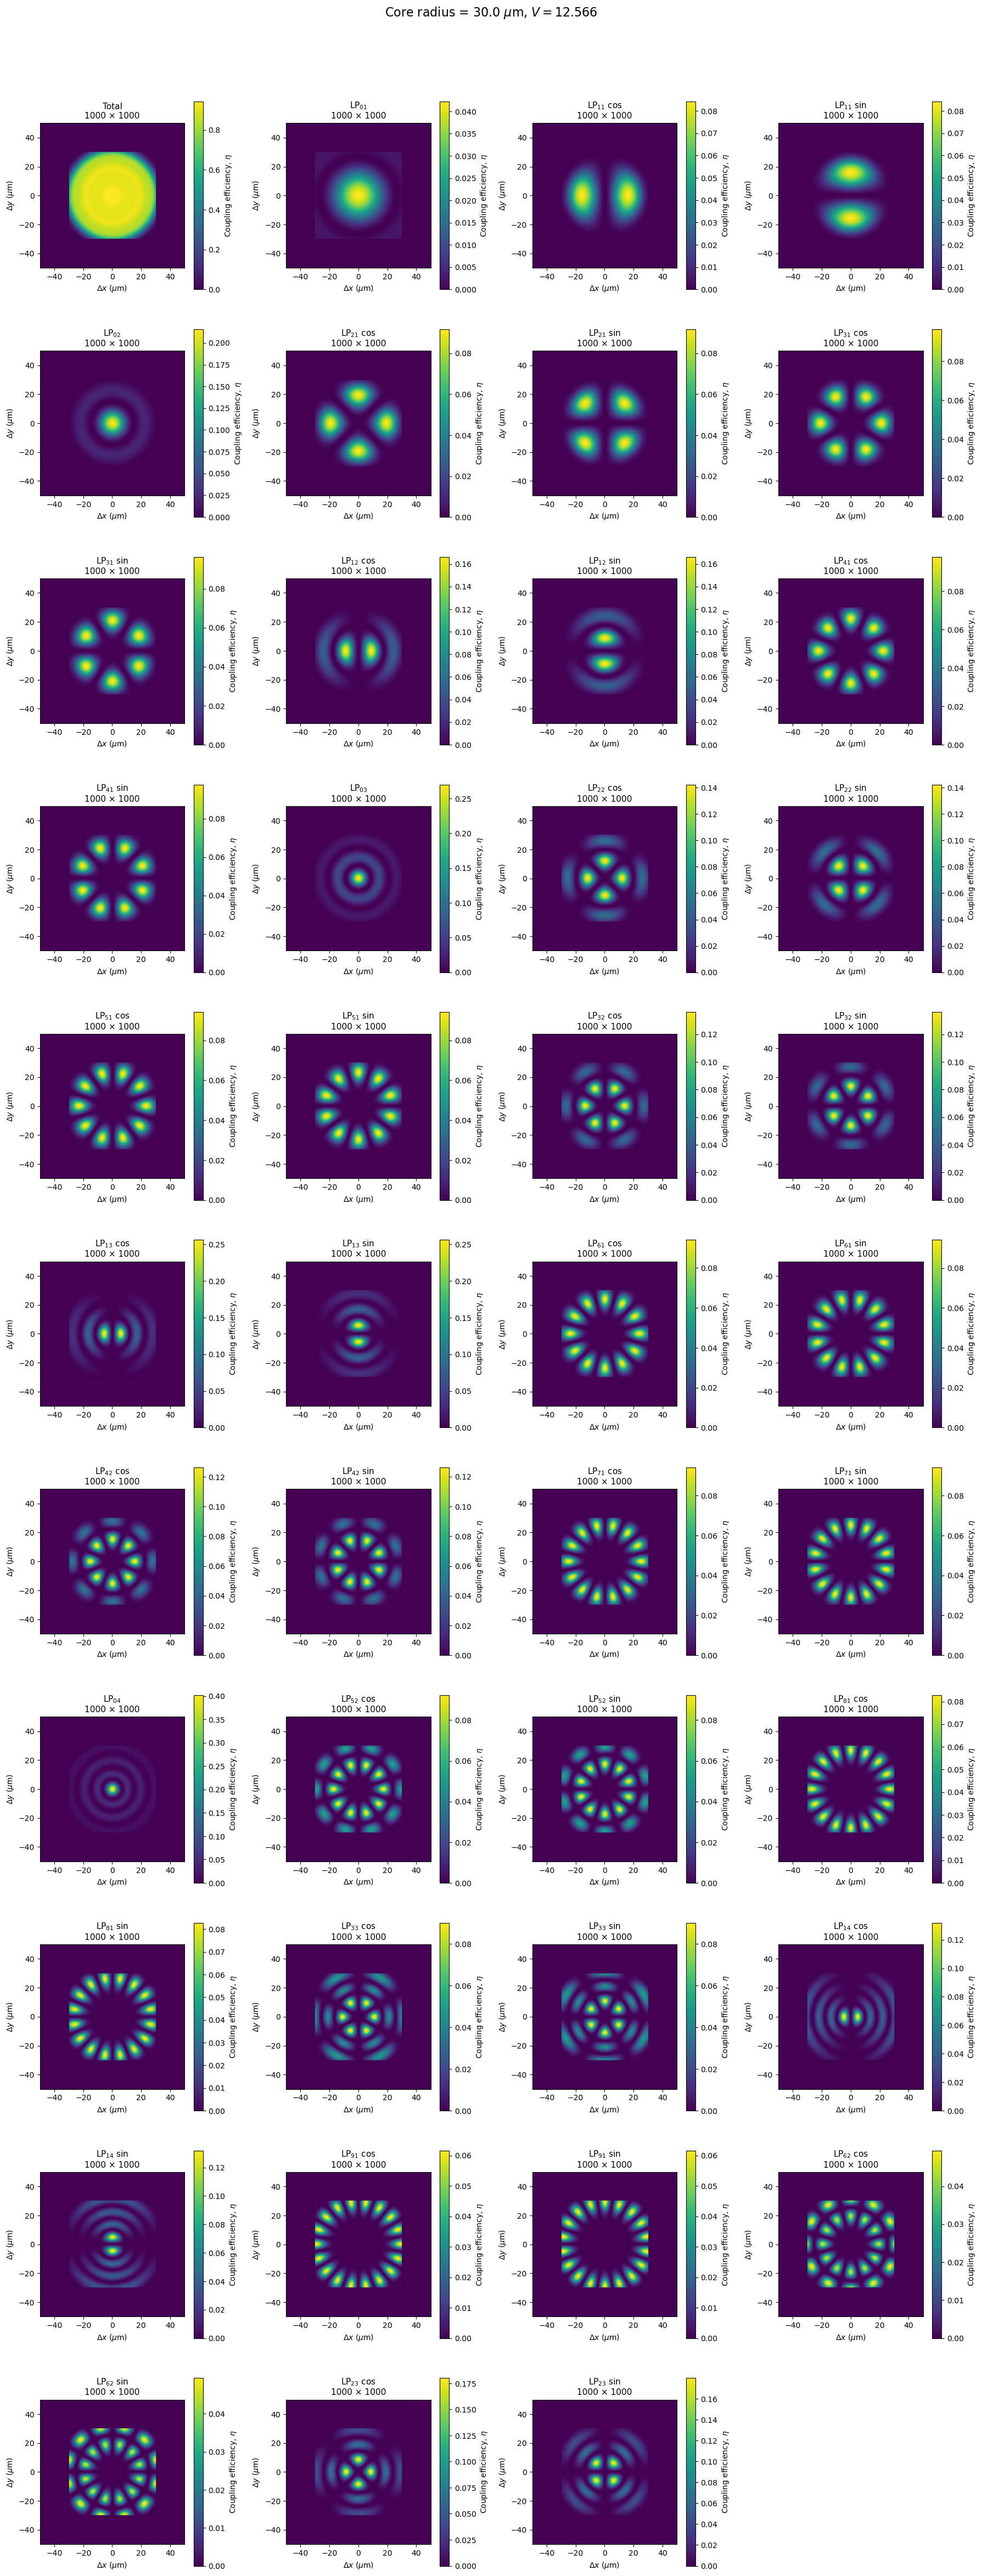

In [34]:
last_result = coupling_maps_continuous[-1]

plot_all_coupling_maps(
    last_result,
    ncols=4,
    cmap="viridis",
    show_shape=True,
)

Requested radius = 5.7 µm
Closest stored radius = 5.700 µm
V = 2.3876
Total map shape = (1000, 1000)
Core radius a = 5.700 µm
V = 2.3876
Total map shape = (1000, 1000)
Number of individual mode maps = 1


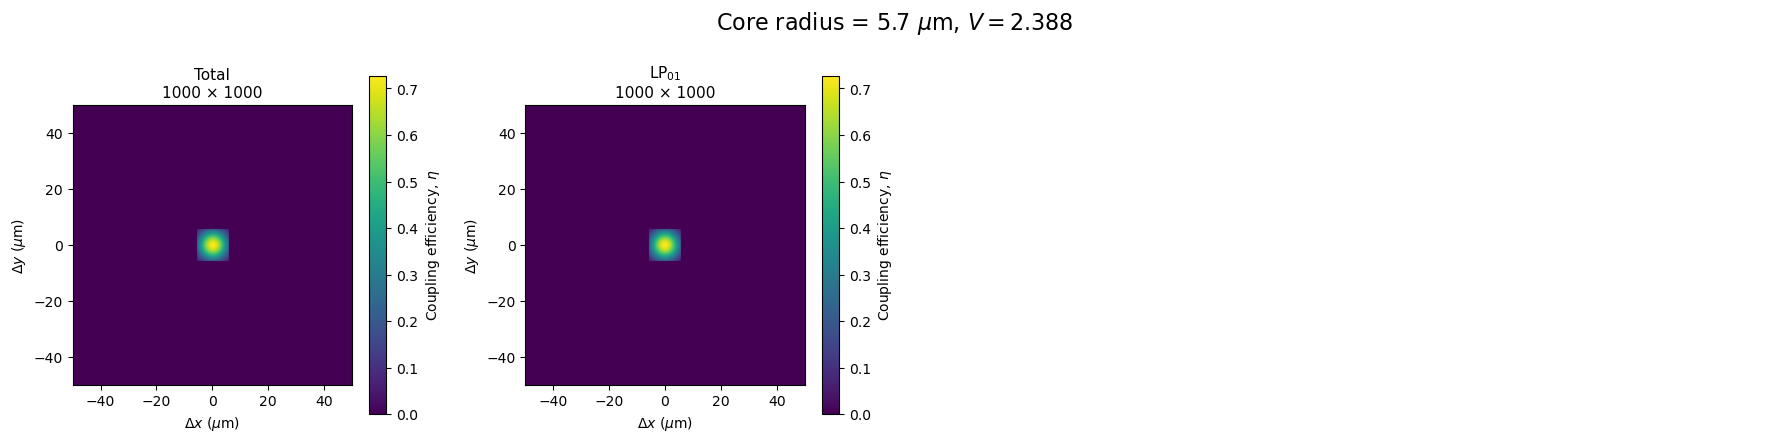

In [35]:
target_radius_um = 5.7
target_radius_m = target_radius_um * 1e-6

a_all = np.array([
    result["a"]
    for result in coupling_maps_continuous
])

idx = np.argmin(
    np.abs(a_all - target_radius_m)
)

result_5p7um = coupling_maps_continuous[idx]

print(
    f"Requested radius = {target_radius_um:.1f} µm"
)

print(
    f"Closest stored radius = "
    f"{result_5p7um['a'] * 1e6:.3f} µm"
)

print(
    f"V = {result_5p7um['V']:.4f}"
)

print(
    f"Total map shape = "
    f"{result_5p7um['eta_total_map'].shape}"
)

plot_all_coupling_maps(
    result_5p7um,
    ncols=4,
    cmap="viridis",
    show_shape=True,
)

Requested radius = 2.5 µm
Closest stored radius = 2.500 µm
V = 1.0472
Total map shape = (1000, 1000)
Core radius a = 2.500 µm
V = 1.0472
Total map shape = (1000, 1000)
Number of individual mode maps = 1


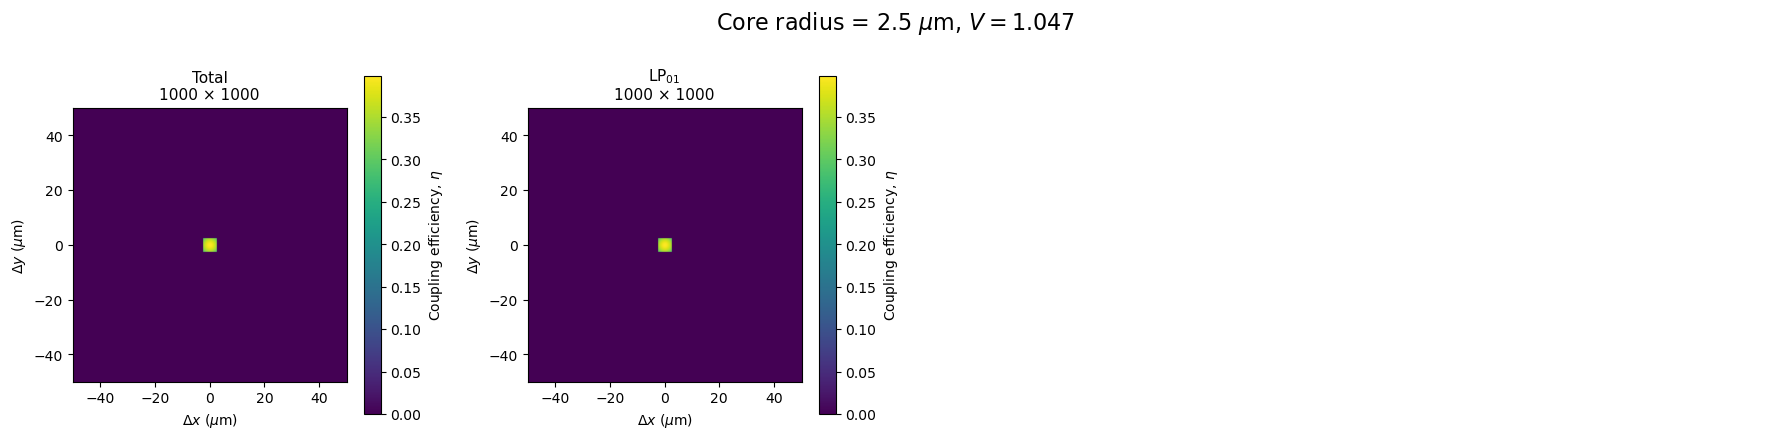

In [36]:
target_radius_um = 2.5
target_radius_m = target_radius_um * 1e-6

a_all = np.array([
    result["a"]
    for result in coupling_maps_continuous
])

idx = np.argmin(
    np.abs(a_all - target_radius_m)
)

result_2p5um = coupling_maps_continuous[idx]

print(
    f"Requested radius = {target_radius_um:.1f} µm"
)

print(
    f"Closest stored radius = "
    f"{result_2p5um['a'] * 1e6:.3f} µm"
)

print(
    f"V = {result_2p5um['V']:.4f}"
)

print(
    f"Total map shape = "
    f"{result_2p5um['eta_total_map'].shape}"
)

plot_all_coupling_maps(
    result_2p5um,
    ncols=4,
    cmap="viridis",
    show_shape=True,
)

In [37]:
def Monte_Carlo_point_source_coupling(
        result, 
        delta_x, delta_y,
        acceptance_radius="core_radius",
        fibre_x=0.0,
        fibre_y=0.0
):
    """
    Perform a Monte Carlo simulation to calculate the coupling efficiency
    of a point source in the presence of tip-tilt jitter. 

    For each random jitter position, the total and individual fibre-mode
    coupling efficiencies are interpolated directly from the original
    saved 2D coupling-efficiency maps.

    This avoids snapping the jitter position to the nearest map pixel.

    Parameters
    ----------
    result : dict
        Coupling-map result for one fibre core radius.

        Must contain:
            "a"
            "V"
            "decentre_x_1d"
            "decentre_y_1d"
            "eta_total_map"
            "mode_eta_maps"

    delta_x : 1D array
        Random x-direction jitter displacements at the fibre plane,
        in metres.

    delta_y : 1D array
        Random y-direction jitter displacements at the fibre plane,
        in metres.

    acceptance_radius : "core_radius", float, or None
        Radius of the circular acceptance region, in metres.

        If "core_radius", the acceptance radius is equal to the
        current fibre core radius.

        If None, no additional circular acceptance boundary is applied.

        If a radius is given, coupling is set to zero when the point
        source is outside this radius.

    fibre_x : float
        Fixed x-position of the fibre centre relative to the nominal
        source position, in metres.

    fibre_y : float
        Fixed y-position of the fibre centre relative to the nominal
        source position, in metres.

    Returns
    -------
    dict
        Monte Carlo coupling results for the current fibre core radius.
    """
    delta_x = np.asarray(delta_x)
    delta_y = np.asarray(delta_y)

    if delta_x.shape != delta_y.shape: 
        raise ValueError(
            "delta_x and delta_y must have the same shape."
        )

    # Number of Monte Carlo samples determined by the number of jitter positions provided.
    n_samples = len(delta_x)

    # Fibre core radius for the coupling map
    a = result["a"]

    # ---------------------------------------------------------
    # Effective source position relative to the actual fibre centre
    # ---------------------------------------------------------

    # Here fibre_x/y describe where the fibre centre is relative
    # to the nominal optical axis.
    # Therefore:
    # source relative to fibre = source position - fibre position.
    effective_delta_x = delta_x - fibre_x
    effective_delta_y = delta_y - fibre_y

    # Calculate the radial displacement of every jitter position. 
    radial_displacement = np.sqrt(effective_delta_x**2 + effective_delta_y**2)

    # Acceptance radius
    if acceptance_radius == "core_radius":
        acceptance_radius = a
    
    else:
        acceptance_radius = acceptance_radius

    # Determine which jittered point-source positions are within the acceptance radius.
    if acceptance_radius is not None:
        inside_acceptance = radial_displacement <= acceptance_radius
    
    else: 
        inside_acceptance = np.ones(n_samples, dtype=bool)
    
    # Original saved coupling-map coordinates for this core radius.
    x_map = result["decentre_x_1d"]
    y_map = result["decentre_y_1d"]

    # Positions that will actually be evaluated (those inside the acceptance radius).
    valid_indices = np.where(inside_acceptance)[0]

    # Regular expects coordinates in the same order as the map axes: (y, x).
    jitter_positions = np.column_stack((
        effective_delta_y[valid_indices],
        effective_delta_x[valid_indices]
    ))

    # ---------------------------------------------------------
    # Total coupling efficiency
    # ---------------------------------------------------------

    # Store the total coupling efficiency for every jitter position.
    # Positions outside the acceptance radius remain zero.
    eta_total_samples = np.zeros(
        n_samples,
        dtype=np.float32
    )

    # Create an interpolator for the total coupling-efficiency map.
    # The map is indexed as [y, x], so the coordinate arrays must
    # be supplied to RegularGridInterpolator in the order (y_map, x_map).
    total_interpolator = RegularGridInterpolator(
        (y_map, x_map),
        result["eta_total_map"],
        method="linear",
        bounds_error=False,
        fill_value=0.0
    )

    # Evaluate the total coupling efficiency at the exact jitter positions
    # that lie inside the acceptance radius.
    #
    # Linear interpolation is used between the original saved map points,
    # rather than snapping each jitter position to the nearest pixel.
    eta_total_samples[valid_indices] = (
        total_interpolator(
            jitter_positions
        )
    )

    # ---------------------------------------------------------
    # Individual mode coupling efficiencies
    # ---------------------------------------------------------

    # Store one array of Monte Carlo coupling efficiencies
    # for every individual fibre-mode component.
    eta_mode_samples = {}

    # Loop through every individual mode coupling map saved
    # for the current fibre core radius.
    for mode_key, eta_mode_map in result["mode_eta_maps"].items():

        # The saved mode key contains:
        #     l       = azimuthal mode index
        #     m       = radial mode index
        #     angular = "cos" or "sin"
        l, m, angular = mode_key

        # Create a readable label for the current fibre mode.
        # Modes with l = 0 only have one angular component.
        if l == 0:
            mode_label = f"LP0{m}"

        else:
            mode_label = (
                f"LP{l}{m} "
                f"{angular}"
            )

        # Initialise the coupling efficiency at every jitter position to zero.
        # Positions outside the acceptance radius therefore remain zero.
        mode_samples = np.zeros(
            n_samples,
            dtype=np.float32
        )

        # Create an interpolator for the current individual-mode
        # coupling-efficiency map.
        mode_interpolator = RegularGridInterpolator(
            (y_map, x_map),
            eta_mode_map,
            method="linear",
            bounds_error=False,
            fill_value=0.0
        )

        # Evaluate this mode's coupling efficiency at the exact same
        # jitter positions used for the total coupling-efficiency map.
        mode_samples[valid_indices] = (
            mode_interpolator(
                jitter_positions
            )
        )

        # Store the coupling efficiency of this mode for every
        # Monte Carlo jitter position.
        eta_mode_samples[
            mode_label
        ] = mode_samples

    # ---------------------------------------------------------
    # Jitter-averaged coupling efficiencies
    # ---------------------------------------------------------

    # Calculate the mean total coupling efficiency over all Monte Carlo
    # jitter positions, including zero coupling for positions outside
    # the acceptance radius.
    eta_total_mean = np.mean(
        eta_total_samples
    )

    # Calculate the mean coupling efficiency of every individual
    # fibre-mode component over all Monte Carlo jitter positions.
    eta_mode_mean = {
        mode_label: np.mean(mode_samples)
        for mode_label, mode_samples
        in eta_mode_samples.items()
    }

    # ---------------------------------------------------------
    # Return results
    # ---------------------------------------------------------

    # Return both the individual Monte Carlo samples and their means
    # so that the jitter distribution can be analysed later if required.
    return {
        "core_radius": a,
        "V": result["V"],

        "eta_total_mean":
            eta_total_mean,

        "eta_total_samples":
            eta_total_samples,

        "eta_mode_mean":
            eta_mode_mean,

        "eta_mode_samples":
            eta_mode_samples,

        "inside_acceptance":
            inside_acceptance,

        "effective_delta_x":
            effective_delta_x,

        "effective_delta_y":
            effective_delta_y,
    }

In [38]:
# from joblib import Parallel, delayed


def jittered_point_src_eta_per_mode_from_saved_maps(
        coupling_results_all,
        delta_x,
        delta_y,
        acceptance_radius="core_radius",
        fibre_offset_x=0.0,
        fibre_offset_y=0.0,
        n_jobs=1,
):
    """
    Calculate the jitter-averaged point-source coupling efficiency
    for the total guided power and every individual fibre-mode
    component as a function of fibre core radius.

    Coupling efficiencies are interpolated directly from the
    original saved 2D coupling-efficiency maps.
    """

    delta_x = np.asarray(
        delta_x
    )

    delta_y = np.asarray(
        delta_y
    )

    if delta_x.shape != delta_y.shape:
        raise ValueError(
            "delta_x and delta_y must have the same shape."
        )

    # ---------------------------------------------------------
    # Calculate one fibre core radius
    # ---------------------------------------------------------

    def run_one_radius(result):

        return (
            Monte_Carlo_point_source_coupling(
                result=result,

                delta_x=delta_x,
                delta_y=delta_y,

                acceptance_radius=
                    acceptance_radius,

                fibre_x=
                    fibre_offset_x,

                fibre_y=
                    fibre_offset_y,
            )
        )

    # ---------------------------------------------------------
    # Parallel processing over fibre core radius
    # ---------------------------------------------------------

    if n_jobs == 1:

        results_all_radius = [
            run_one_radius(result)
            for result
            in coupling_results_all
        ]

    else:

        results_all_radius = Parallel(
            n_jobs=n_jobs,
            backend="threading",
            verbose=10
        )(
            delayed(run_one_radius)(
                result
            )
            for result
            in coupling_results_all
        )

    # Make sure results remain ordered by core radius.
    results_all_radius = sorted(
        results_all_radius,
        key=lambda result:
            result["core_radius"]
    )

    return results_all_radius

In [39]:
delta_x, delta_y = generate_jitter_positions(
    sigma_jitter_rms_mas=20.0,  # RMS jitter in milliarcseconds
    focal_length=f_coude,  # Focal length of the telescope in metres
    demagnification=Magnification,  # Demagnification factor
    n_samples=1000,  # Number of random jitter positions
    rng=np.random.default_rng(seed=42)  # Random number generator with a fixed seed
)

In [40]:
eta_samples_point_5p7 = (
    Monte_Carlo_point_source_coupling(
        delta_x=delta_x,
        delta_y=delta_y,
        result=result_5p7um,
        acceptance_radius="core_radius",
        fibre_x=0.0,
        fibre_y=0.0
    )
)

In [41]:
eta_total_5p7 = eta_samples_point_5p7["eta_total_samples"]

print(
    "Number of Monte Carlo samples:",
    len(eta_total_5p7)
)

print(
    "Mean coupling efficiency:",
    np.mean(eta_total_5p7)
)

print(
    "Standard deviation:",
    np.std(
        eta_total_5p7,
        ddof=1
    )
)

print(
    "Standard error:",
    np.std(
        eta_total_5p7,
        ddof=1
    )
    / np.sqrt(
        len(eta_total_5p7)
    )
)

Number of Monte Carlo samples: 1000
Mean coupling efficiency: 0.32393354
Standard deviation: 0.2608013
Standard error: 0.008247260788965892


In [42]:
coupling_results_all = []

for bin_id in sorted(coupling_bins.keys()):

    for result in coupling_bins[bin_id]["results"]:

        coupling_results_all.append(
            result
        )

coupling_results_all = sorted(
    coupling_results_all,
    key=lambda result: result["a"]
)

In [43]:
results_jitter = (
    jittered_point_src_eta_per_mode_from_saved_maps(
        coupling_results_all=coupling_results_all,
        delta_x=delta_x,
        delta_y=delta_y,
        acceptance_radius="core_radius",
        fibre_offset_x=0.0,
        fibre_offset_y=0.0,
        n_jobs=4
    )
)

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.2s
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:    0.3s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:    0.4s
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:    0.5s
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:    0.7s
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:    0.8s
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed:    1.0s
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:    1.2s
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:    1.2s
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed:    1.2s
[Para

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import math


def plot_jittered_point_source_efficiency_asymmetric_modes(
        results,
        title="Jitter-averaged point-source coupling efficiency of asymmetric LP modes",
):
    """
    Plot the total jitter-averaged point-source coupling efficiency
    and the individual asymmetric LP-mode components.

    Asymmetric modes are identified from labels containing:
        " cos"
        " sin"

    The cos/sin pair for each LP family shares the same colour.

    Parameters
    ----------
    results : list of dict
        Output from
        jittered_point_src_eta_per_mode_from_saved_maps().

        Each result must contain:
            "core_radius"
            "eta_total_mean"
            "eta_mode_mean"
    """

    # ---------------------------------------------------------
    # Extract fibre core radii
    # ---------------------------------------------------------

    # Core radius corresponding to each Monte Carlo result.
    core_radius_array = np.array([
        result["core_radius"]
        for result in results
    ])

    # ---------------------------------------------------------
    # Extract total coupling efficiency
    # ---------------------------------------------------------

    # Total jitter-averaged coupling efficiency as a function
    # of fibre core radius.
    eta_total_mean = np.array([
        result["eta_total_mean"]
        for result in results
    ])

    # ---------------------------------------------------------
    # Find all asymmetric mode labels
    # ---------------------------------------------------------

    # Find every individual mode label that appears at any
    # fibre core radius.
    all_mode_labels = sorted(
        set(
            mode_label
            for result in results
            for mode_label in result["eta_mode_mean"].keys()
        )
    )

    # Keep only asymmetric modes, which have separate
    # cosine and sine angular components.
    asymmetric_mode_labels = [
        label
        for label in all_mode_labels
        if (" cos" in label) or (" sin" in label)
    ]

    # ---------------------------------------------------------
    # Store each mode as a function of core radius
    # ---------------------------------------------------------

    asymmetric_mode_eta_dict = {}

    for mode_label in asymmetric_mode_labels:

        # If a mode does not yet exist at a particular core radius,
        # store NaN so that Matplotlib does not draw a zero-valued line
        # before that mode reaches cutoff.
        asymmetric_mode_eta_dict[mode_label] = np.array([
            result["eta_mode_mean"].get(
                mode_label,
                np.nan
            )
            for result in results
        ])

    # ---------------------------------------------------------
    # Identify LP families
    # ---------------------------------------------------------

    # Base mode names:
    # LP11, LP21, LP31, ...
    #
    # LP11 cos and LP11 sin therefore belong to the same LP11 family.
    base_modes = sorted(
        set(
            label.split()[0]
            for label in asymmetric_mode_eta_dict.keys()
        )
    )

    # ---------------------------------------------------------
    # Assign colours
    # ---------------------------------------------------------

    # Give each LP family one colour.
    # The cosine and sine components of the same LP family
    # therefore have the same colour.
    cmap = plt.cm.turbo

    colours = cmap(
        np.linspace(
            0,
            1,
            len(base_modes)
        )
    )

    colour_dict = {
        base_mode: colours[i]
        for i, base_mode in enumerate(base_modes)
    }

    # ---------------------------------------------------------
    # Create figure
    # ---------------------------------------------------------

    fig, ax1 = plt.subplots(
        figsize=(10, 6)
    )

    # ---------------------------------------------------------
    # Total jitter-averaged coupling efficiency
    # ---------------------------------------------------------

    ax1.plot(
        core_radius_array * 1e6,
        eta_total_mean,
        color="black",
        linewidth=2,
        label=(
            r"Total jitter-averaged coupling efficiency, "
            r"$\eta_{\mathrm{psf}}$"
        )
    )

    # ---------------------------------------------------------
    # Shade single-mode region
    # ---------------------------------------------------------

    V_1_2 = 1.2
    V_2_405 = 2.405

    ax1.axvspan(
        V_to_radius_um(V_1_2),
        V_to_radius_um(V_2_405),
        color="lightgrey",
        alpha=0.5,
        label=r"$1.2 < V < 2.405$"
    )

    # ---------------------------------------------------------
    # Plot asymmetric LP-mode components
    # ---------------------------------------------------------

    mode_lines = {}

    for base_mode in base_modes:

        cos_label = (
            f"{base_mode} cos"
        )

        sin_label = (
            f"{base_mode} sin"
        )

        colour = (
            colour_dict[base_mode]
        )

        # Cosine component.
        if cos_label in asymmetric_mode_eta_dict:

            line_cos, = ax1.plot(
                core_radius_array * 1e6,
                asymmetric_mode_eta_dict[
                    cos_label
                ],
                linestyle="dashed",
                linewidth=1.5,
                alpha=0.9,
                color=colour,
                label=cos_label
            )

            mode_lines[
                cos_label
            ] = line_cos

        # Sine component.
        if sin_label in asymmetric_mode_eta_dict:

            line_sin, = ax1.plot(
                core_radius_array * 1e6,
                asymmetric_mode_eta_dict[
                    sin_label
                ],
                linestyle="dotted",
                linewidth=1.8,
                alpha=0.9,
                color=colour,
                label=sin_label
            )

            mode_lines[
                sin_label
            ] = line_sin

    # ---------------------------------------------------------
    # Axis labels
    # ---------------------------------------------------------

    ax1.set_xlabel(
        "Core radius (µm)",
        fontsize=16,
        labelpad=8
    )

    ax1.set_ylabel(
        r"Jitter-averaged coupling efficiency, "
        r"$\eta_{\mathrm{psf}}$",
        fontsize=16,
        labelpad=8
    )

    # ax1.set_title(
    #     title,
    #     fontsize=15
    # )

    ax1.tick_params(
        axis="x",
        labelsize=14
    )

    ax1.tick_params(
        axis="y",
        labelsize=14
    )

    ax1.minorticks_on()

    ax1.grid(
        True,
        alpha=0.3
    )

    # ---------------------------------------------------------
    # Top x-axis: normalised frequency V
    # ---------------------------------------------------------

    ax_top = ax1.secondary_xaxis(
        "top",
        functions=(
            radius_um_to_V,
            V_to_radius_um
        )
    )

    ax_top.set_xlabel(
        "Normalised frequency, V",
        fontsize=14,
        labelpad=8
    )

    ax_top.tick_params(
        axis="x",
        labelsize=14
    )

    ax_top.minorticks_on()

    # ---------------------------------------------------------
    # Legend
    # ---------------------------------------------------------

    handles, labels = (
        ax1.get_legend_handles_labels()
    )

    n_legend_rows = 4

    n_legend_cols = math.ceil(
        len(labels)
        / n_legend_rows
    )

    ax1.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(
            0.0,
            1.0,
            1.0,
            0.0
        ),
        bbox_transform=ax1.transAxes,
        ncol=n_legend_cols,
        mode="expand",
        fontsize=8,
        frameon=True,
        columnspacing=0.8,
        handlelength=1.6,
        handletextpad=0.4,
        borderaxespad=0.4
    )

    plt.tight_layout()
    plt.show()

    return (
        asymmetric_mode_eta_dict,
        mode_lines
    )

In [45]:
def radius_um_to_V(radius_um):
    radius_m = radius_um * 1e-6
    return 2 * np.pi * radius_m * NA / lam0

def V_to_radius_um(V):
    radius_m = V * lam0 / (2 * np.pi * NA)
    return radius_m * 1e6


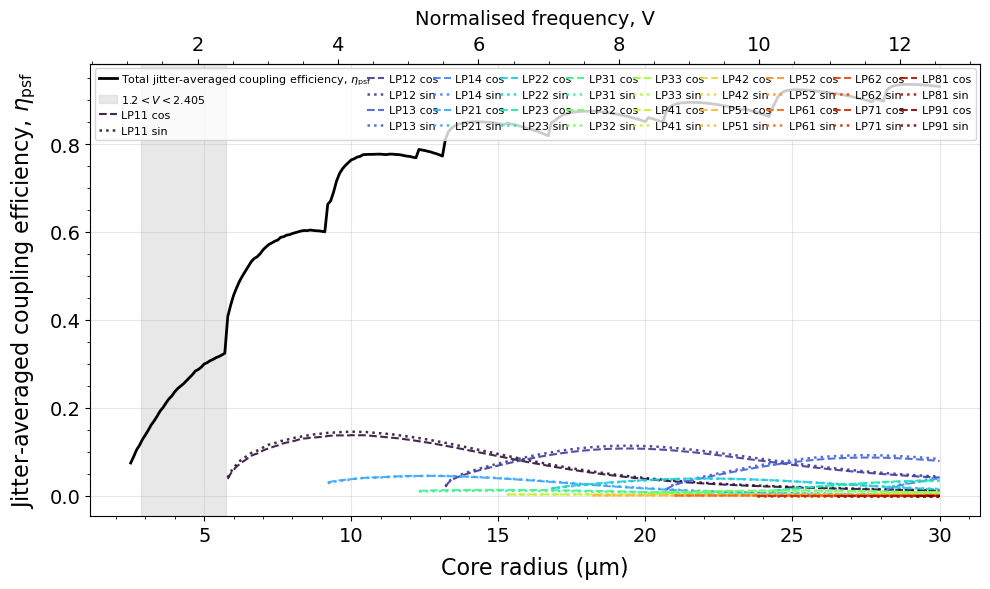

In [46]:
asymmetric_mode_eta_dict, mode_lines = (
    plot_jittered_point_source_efficiency_asymmetric_modes(
        results_jitter
    )
)

In [47]:
delta_x_300, delta_y_300 = generate_jitter_positions(
    sigma_jitter_rms_mas=20.0,  # RMS jitter in milliarcseconds
    focal_length=f_coude,  # Focal length of the telescope in metres
    demagnification=Magnification,  # Demagnification factor
    n_samples=300,  # Number of random jitter positions
    rng=np.random.default_rng(seed=42)  # Random number generator with a fixed seed
)

In [48]:
results_jitter_test300 = (
    jittered_point_src_eta_per_mode_from_saved_maps(
        coupling_results_all=coupling_results_all,
        delta_x=delta_x_300,
        delta_y=delta_y_300,
        acceptance_radius="core_radius",
        fibre_offset_x=0.0,
        fibre_offset_y=0.0,
        n_jobs=1
    )
)

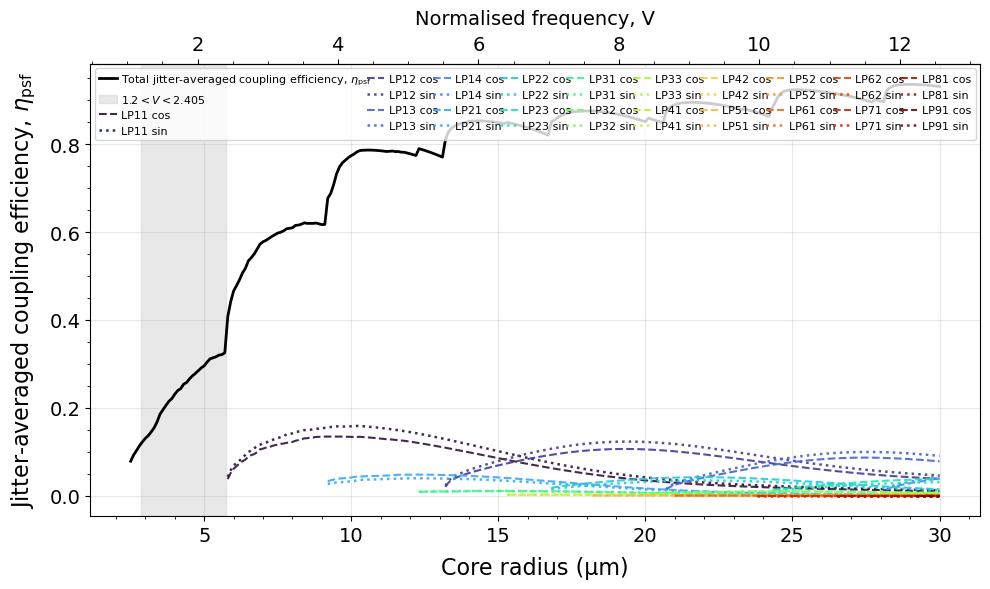

In [49]:
asymmetric_mode_eta_dict, mode_lines = (
    plot_jittered_point_source_efficiency_asymmetric_modes(
        results_jitter_test300
    )
)

In [50]:
seeds = [1,2,3,4,5]

results_all_seeds = []

for seed in seeds:

    rng = np.random.default_rng(seed)

    delta_x_seed, delta_y_seed = generate_jitter_positions(
        sigma_jitter_rms_mas=20.0,  # RMS jitter in milliarcseconds
        focal_length=f_coude,  # Focal length of the telescope in metres
        demagnification=Magnification,  # Demagnification factor
        n_samples=1000,  # Number of random jitter positions
        rng=rng  # Random number generator with a fixed seed
    )

    results_jitter_seed = jittered_point_src_eta_per_mode_from_saved_maps(
        coupling_results_all=coupling_results_all,
        delta_x=delta_x_seed,
        delta_y=delta_y_seed,
        acceptance_radius="core_radius",
        fibre_offset_x=0.0,
        fibre_offset_y=0.0,
        n_jobs=4
    )
    results_all_seeds.append(results_jitter_seed)

    print(
        f"Completed seed {seed} "
        f"({len(results_all_seeds)}/{len(seeds)})"
    )

[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed:    0.2s
[Para

Completed seed 1 (1/5)


[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed:    0.2s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    0.2s
[Parallel(n_jobs=4)]: Done 213 tasks      | elapsed:    0.3s
[Parallel(n_jobs=4)]: Done 234 tasks      | elapsed:    0.4s
[Parallel(n_jobs=4)]: Done 257 tasks      | elapsed:    0.4s
[Parallel(n_jobs=4)]: Done 276 out of 276 | elapsed:    0.5s finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:    0

Completed seed 2 (2/5)


[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed:    0.2s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    0.2s
[Parallel(n_jobs=4)]: Done 213 tasks      | elapsed:    0.3s
[Parallel(n_jobs=4)]: Done 234 tasks      | elapsed:    0.4s
[Parallel(n_jobs=4)]: Done 257 tasks      | elapsed:    0.4s
[Parallel(n_jobs=4)]: Done 276 out of 276 | elapsed:    0.5s finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    0

Completed seed 3 (3/5)


[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed:    0.2s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    0.2s
[Parallel(n_jobs=4)]: Done 213 tasks      | elapsed:    0.3s
[Parallel(n_jobs=4)]: Done 234 tasks      | elapsed:    0.4s
[Parallel(n_jobs=4)]: Done 257 tasks      | elapsed:    0.4s
[Parallel(n_jobs=4)]: Done 276 out of 276 | elapsed:    0.5s finished
[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    0.0s


Completed seed 4 (4/5)


[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  77 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done  90 tasks      | elapsed:    0.0s
[Parallel(n_jobs=4)]: Done 105 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 120 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 137 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:    0.1s
[Parallel(n_jobs=4)]: Done 173 tasks      | elapsed:    0.2s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    0.2s
[Parallel(n_jobs=4)]: Done 213 tasks      | elapsed:    0.3s
[Parallel(n_jobs=4)]: Done 234 tasks      | elapsed:    0.3s
[Parallel(n_jobs=4)]: Done 257 tasks      | elapsed:    0.4s


Completed seed 5 (5/5)


[Parallel(n_jobs=4)]: Done 276 out of 276 | elapsed:    0.5s finished


Plotting seed 1


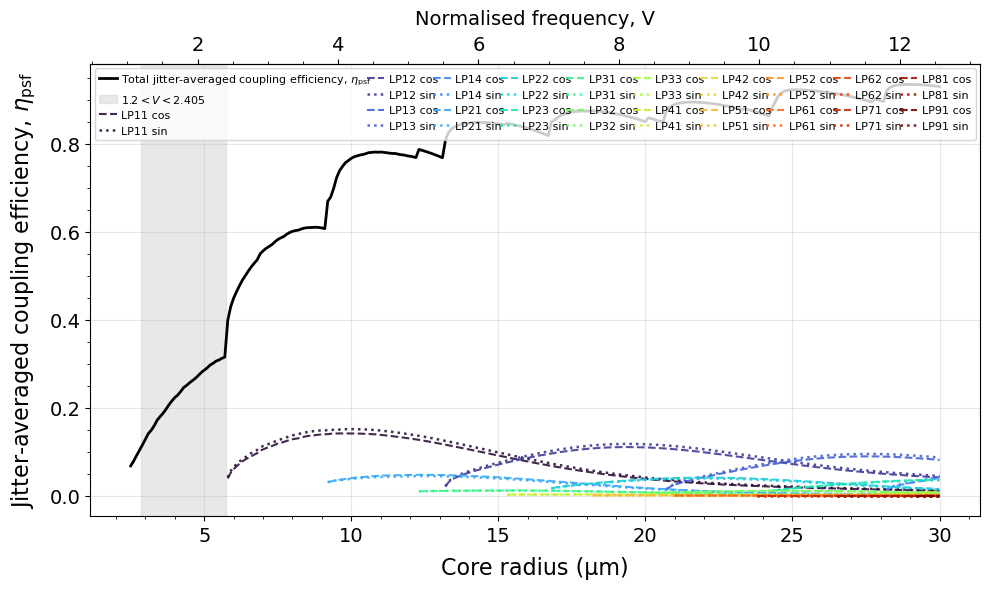

Plotting seed 2


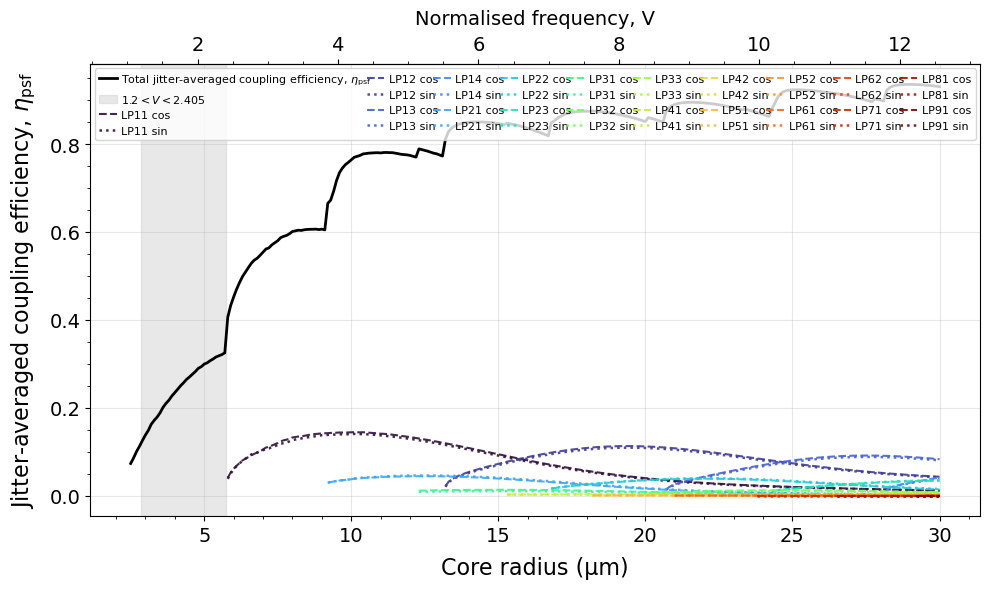

Plotting seed 3


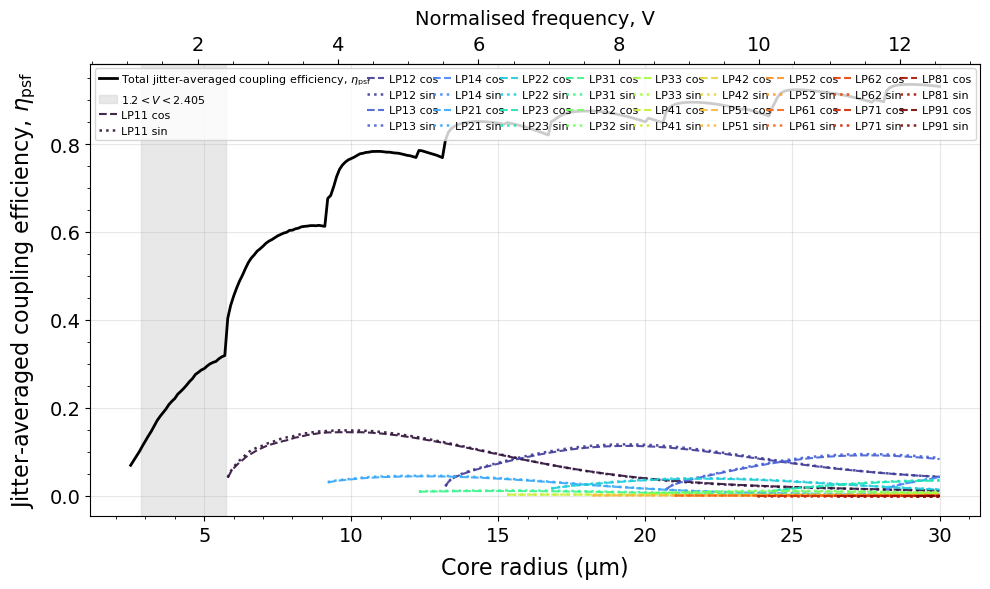

Plotting seed 4


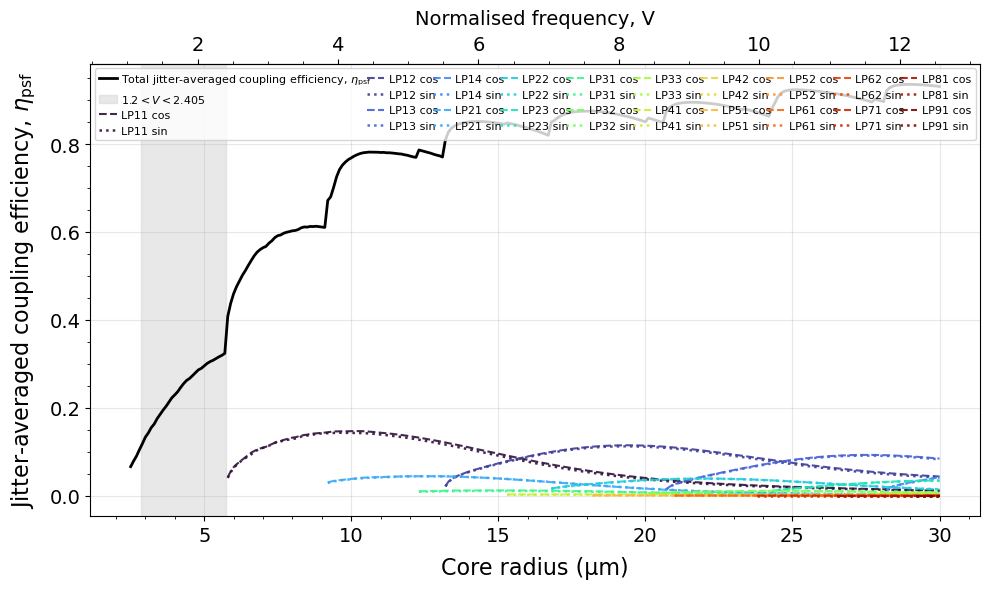

Plotting seed 5


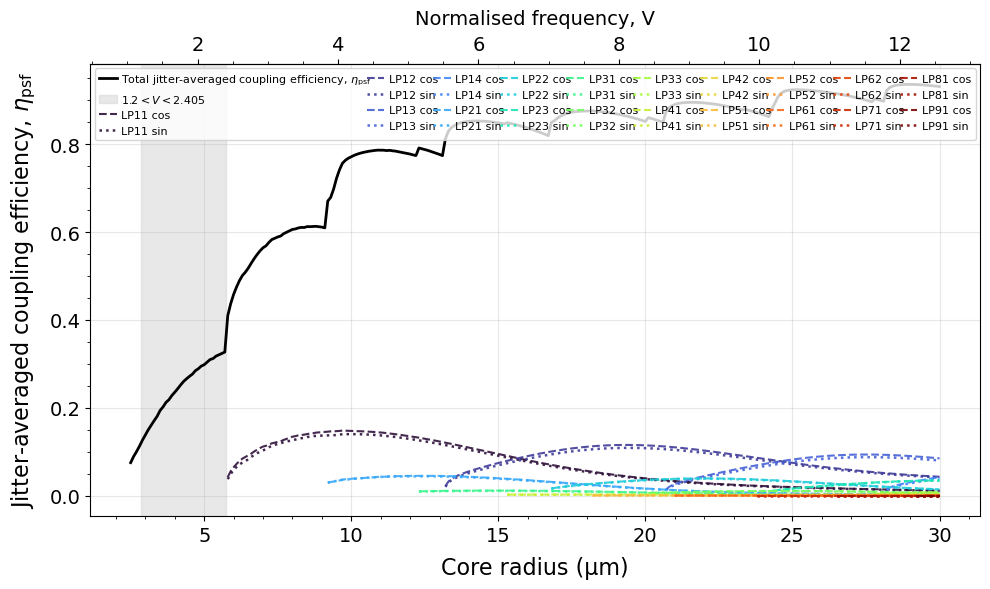

In [51]:
for seed, results_seed in zip(
    seeds,
    results_all_seeds
):

    print(
        f"Plotting seed {seed}"
    )

    plot_jittered_point_source_efficiency_asymmetric_modes(
        results=results_seed,
        title=(
            "Jitter-averaged point-source coupling efficiency "
            f"of asymmetric LP modes — seed {seed}"
        )
    )

In [52]:
results_jitter_average = []

n_radii = len(
    results_all_seeds[0]
)

for i in range(n_radii):

    # All results for this same core radius
    # from the different random seeds.
    radius_results = [
        results_seed[i]
        for results_seed in results_all_seeds
    ]

    # ---------------------------------------------------------
    # Total coupling
    # ---------------------------------------------------------

    eta_total_seed_values = np.array([
        result["eta_total_mean"]
        for result in radius_results
    ])

    eta_total_mean = np.mean(
        eta_total_seed_values
    )

    eta_total_std_seeds = np.std(
        eta_total_seed_values,
        ddof=1
    )

    # ---------------------------------------------------------
    # Individual modes
    # ---------------------------------------------------------

    mode_labels = (
        radius_results[0][
            "eta_mode_mean"
        ].keys()
    )

    eta_mode_mean = {}

    eta_mode_std_seeds = {}

    for mode_label in mode_labels:

        mode_seed_values = np.array([
            result[
                "eta_mode_mean"
            ][mode_label]
            for result in radius_results
        ])

        eta_mode_mean[mode_label] = (
            np.mean(
                mode_seed_values
            )
        )

        eta_mode_std_seeds[mode_label] = (
            np.std(
                mode_seed_values,
                ddof=1
            )
        )

    # ---------------------------------------------------------
    # Store averaged result
    # ---------------------------------------------------------

    results_jitter_average.append({
        "core_radius":
            radius_results[0]["core_radius"],

        "V":
            radius_results[0]["V"],

        "eta_total_mean":
            eta_total_mean,

        "eta_total_std_seeds":
            eta_total_std_seeds,

        "eta_mode_mean":
            eta_mode_mean,

        "eta_mode_std_seeds":
            eta_mode_std_seeds,
    })

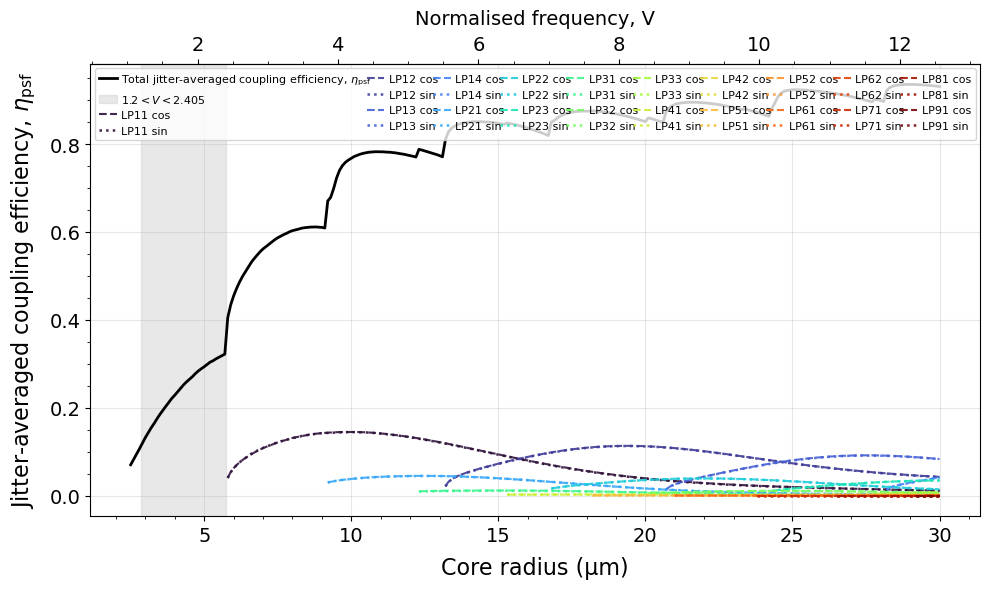

({'LP11 cos': array([       nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan, 0.04071718, 0.05374108,
         0.06247614, 0.06942555, 0.07551857, 0.08100595, 0.08559241,
         0.08994161, 0.09390141, 0.09786975, 0.10135816, 0.10498373,
         0.1081385 , 0.11087205, 0.11342913, 0.11600397, 0.11839573,
         0.12080862, 0.12272985, 0.12515537, 0.12700436, 0.12930216,
         0.13129906, 0.13261263, 0.13395768, 0.1353385 , 0.13648996,
         0.13783717, 0.1391343 , 0.13984773, 0.14085221, 0.14153019,
         0.14224927, 0.14260745, 0.14308271, 0.14362927, 0.14404945,
         0.14436179, 0

In [53]:
plot_jittered_point_source_efficiency_asymmetric_modes(
    results_jitter_average
)

In [54]:
def plot_jittered_point_source_efficiency_asymmetric_mode_families(
    core_radius_array,
    results,
    title="Jitter-averaged point-source coupling efficiency of asymmetric LP modes",
):
    """
    Plot total jitter-averaged point-source coupling efficiency
    and the total coupling efficiency of each asymmetric LP mode family.

    For each asymmetric LP mode family:
        eta_LP = eta_cos + eta_sin

    Each LP mode family is shown using a different colour and line style.
    """

    # Extract the total jitter-averaged coupling efficiency.
    eta_total_mean = np.array([
        result["eta_total_mean"]
        for result in results
    ])

    # Find all mode labels present in the results.
    all_mode_labels = sorted(
        set(
            mode_label
            for result in results
            for mode_label in result["eta_mode_mean"].keys()
        )
    )

    # Keep only asymmetric modes.
    asymmetric_mode_labels = [
        label
        for label in all_mode_labels
        if (" cos" in label) or (" sin" in label)
    ]

    # Base mode names: LP11, LP21, LP31, ...
    base_modes = set(
        label.split()[0]
        for label in asymmetric_mode_labels
    )

    # Find the first core radius at which each LP mode family is supported.
    mode_cutoff_V = {}

    for base_mode in base_modes:

        cos_label = f"{base_mode} cos"
        sin_label = f"{base_mode} sin"

        for i, result in enumerate(results):

            eta_mode_mean = result["eta_mode_mean"]

            if (
                cos_label in eta_mode_mean
                or sin_label in eta_mode_mean
            ):
                # Convert the first supported core radius to V.
                mode_cutoff_V[base_mode] = (
                    2 * np.pi
                    * core_radius_array[i]
                    * NA
                    / lam0
                )

                break

    # Sort LP mode families by increasing cutoff V.
    base_modes = sorted(
        base_modes,
        key=lambda mode: mode_cutoff_V[mode]
    )

    # Store the total coupling efficiency of each asymmetric LP family.
    asymmetric_mode_eta_dict = {}

    for base_mode in base_modes:

        cos_label = f"{base_mode} cos"
        sin_label = f"{base_mode} sin"

        eta_family = []

        for result in results:

            eta_mode_mean = result["eta_mode_mean"]

            eta_cos = eta_mode_mean.get(
                cos_label,
                0.0
            )

            eta_sin = eta_mode_mean.get(
                sin_label,
                0.0
            )

            # Calculate the total coupling efficiency of the LP mode family.
            eta_total_mode = (
                eta_cos + eta_sin
            )

            # Do not plot the mode if its coupling efficiency is zero.
            if eta_total_mode == 0.0:
                eta_family.append(np.nan)

            else:
                eta_family.append(
                    eta_total_mode
                )

        asymmetric_mode_eta_dict[base_mode] = np.array(
            eta_family
        )

    # One colour per base LP mode.
    cmap = plt.cm.turbo
    colours = cmap(
        np.linspace(0, 1, len(base_modes))
    )

    colour_dict = {
        base_mode: colours[i]
        for i, base_mode in enumerate(base_modes)
    }

    # One line style per base LP mode.
    linestyles = [
        "--",                       # dashed
        ":",                        # dotted
        "-.",                       # dash-dot
        (0, (5, 2)),                # long dashed
        (0, (3, 1, 1, 1)),         # dash-dot-dot
        (0, (1, 1)),                # densely dotted
        (0, (5, 1, 1, 1)),         # long dash-dot
        (0, (3, 2, 1, 2)),         # short dash-dot
        (0, (5, 2, 1, 2, 1, 2)),   # dash-dot-dot
    ]

    linestyle_dict = {
        base_mode: linestyles[i % len(linestyles)]
        for i, base_mode in enumerate(base_modes)
    }

    # Make sure LP11 is always dashed.
    if "LP11" in linestyle_dict:
        linestyle_dict["LP11"] = "--"

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Total jitter-averaged point-source coupling efficiency.
    total_line, = ax1.plot(
        core_radius_array * 1e6,
        eta_total_mean,
        color="black",
        linewidth=2,
        linestyle="-",
        label=r"Total jitter-averaged coupling efficiency, $\eta_{\mathrm{psf}}$"
    )

    # Shade single-mode region.
    V_1_2 = 1.2
    V_2_405 = 2.405

    single_mode_region = ax1.axvspan(
        V_to_radius_um(V_1_2),
        V_to_radius_um(V_2_405),
        color="lightgrey",
        alpha=0.5,
        label=r"$1.2 < V < 2.405$"
    )

    # Plot the total cos + sin coupling for each asymmetric LP family.
    mode_lines = {}

    for base_mode in base_modes:

        colour = colour_dict[base_mode]
        linestyle = linestyle_dict[base_mode]
        eta_mode = asymmetric_mode_eta_dict[base_mode]

        # Find the points where the coupling efficiency is non-zero.
        valid_indices = np.where(
            np.isfinite(eta_mode)
        )[0]

        # Plot the total cos + sin coupling efficiency.
        line_mode, = ax1.plot(
            core_radius_array[valid_indices] * 1e6,
            eta_mode[valid_indices],
            color=colour,
            linestyle=linestyle,
            linewidth=2,
            label=rf"{base_mode} ($\cos + \sin$)",
            zorder=3
        )

        mode_lines[base_mode] = line_mode

    # Axis labels.
    ax1.set_xlabel(
        "Core radius (µm)",
        fontsize=16,
        labelpad=8
    )

    ax1.set_ylabel(
        r"Jitter-averaged coupling efficiency, $\eta_{\mathrm{psf}}$",
        fontsize=16,
        labelpad=8
    )

    # ax1.set_title(title, fontsize=15)

    ax1.tick_params(
        axis="x",
        labelsize=14
    )

    ax1.tick_params(
        axis="y",
        labelsize=14
    )

    ax1.minorticks_on()
    ax1.grid(True, alpha=0.3)

    # Top x-axis: normalised frequency V.
    ax_top = ax1.secondary_xaxis(
        "top",
        functions=(radius_um_to_V, V_to_radius_um)
    )

    ax_top.set_xlabel(
        "Normalised frequency, V",
        fontsize=14,
        labelpad=8
    )

    ax_top.tick_params(
        axis="x",
        labelsize=14
    )

    ax_top.minorticks_on()

    # ---------------------------------------------------------
    # Legends
    # ---------------------------------------------------------

    # First row: total coupling efficiency.
    # This occupies the full width above the two-column mode legend.
    legend_total = ax1.legend(
        handles=[total_line],
        labels=[
            r"Total jitter-averaged coupling efficiency, $\eta_{\mathrm{psf}}$"
        ],
        loc="upper right",
        bbox_to_anchor=(1.0, 0.875),
        bbox_transform=ax1.transAxes,
        fontsize=8,
        frameon=True,
        handlelength=3.0,
        handletextpad=0.6,
        borderaxespad=0.4
    )

    # Keep the first legend when the second legend is added.
    ax1.add_artist(legend_total)

    # Remaining legend entries.
    remaining_handles = [
        single_mode_region
    ] + [
        mode_lines[base_mode]
        for base_mode in base_modes
    ]

    remaining_labels = [
        r"$1.2 < V < 2.405$"
    ] + [
        rf"{base_mode} ($\cos + \sin$)"
        for base_mode in base_modes
    ]

    # Two-column legend for the single-mode region and LP mode families.
    legend_modes = ax1.legend(
        handles=remaining_handles,
        labels=remaining_labels,
        ncol=2,
        loc="upper right",
        bbox_to_anchor=(1.0, 0.825),
        bbox_transform=ax1.transAxes,
        fontsize=8,
        frameon=True,
        columnspacing=1.2,
        handlelength=3.0,
        handletextpad=0.6,
        borderaxespad=0.4
    )

    plt.tight_layout()
    plt.show()

    return asymmetric_mode_eta_dict, mode_lines

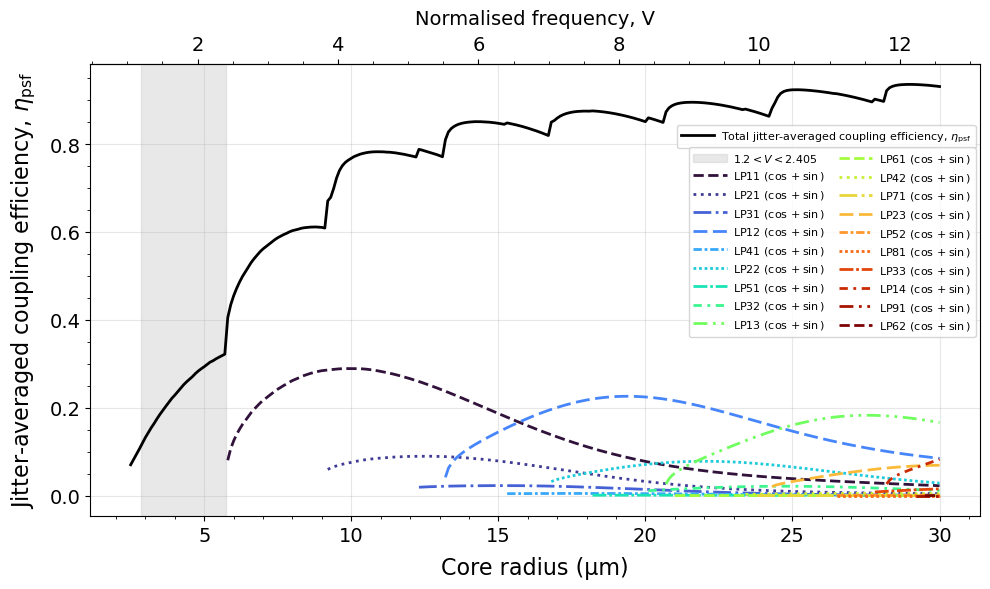

({'LP11': array([       nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan,        nan,        nan,
                nan,        nan,        nan, 0.08047631, 0.10659882,
         0.1244894 , 0.13876544, 0.15102971, 0.16182405, 0.17106435,
         0.18036538, 0.18913904, 0.19676644, 0.20363194, 0.21068802,
         0.21659596, 0.22178976, 0.22703299, 0.23234859, 0.23750275,
         0.24219316, 0.24626547, 0.25044584, 0.25410825, 0.25827482,
         0.26186177, 0.2646535 , 0.26755974, 0.27078885, 0.2733984 ,
         0.27568838, 0.27786946, 0.27967316, 0.28163573, 0.28297162,
         0.28432542, 0.28496805, 0.28581762, 0.2865606 , 0.28737265,
         0.28791797, 0.288

In [55]:
plot_jittered_point_source_efficiency_asymmetric_mode_families(
    core_radius_array=np.linspace(2.5e-6, 30e-6, 276),
    results=results_jitter_average,
    title="Mean jitter-averaged coupling efficiency over all random seeds"
)

In [56]:
for result in results_jitter_average:

    a_um = result["core_radius"] * 1e6

    has_cos = (
        "LP23 cos"
        in result["eta_mode_mean"]
    )

    has_sin = (
        "LP23 sin"
        in result["eta_mode_mean"]
    )

    print(
        f"a = {a_um:.3f} µm | "
        f"cos = {has_cos} | "
        f"sin = {has_sin}"
    )

a = 2.500 µm | cos = False | sin = False
a = 2.600 µm | cos = False | sin = False
a = 2.700 µm | cos = False | sin = False
a = 2.800 µm | cos = False | sin = False
a = 2.900 µm | cos = False | sin = False
a = 3.000 µm | cos = False | sin = False
a = 3.100 µm | cos = False | sin = False
a = 3.200 µm | cos = False | sin = False
a = 3.300 µm | cos = False | sin = False
a = 3.400 µm | cos = False | sin = False
a = 3.500 µm | cos = False | sin = False
a = 3.600 µm | cos = False | sin = False
a = 3.700 µm | cos = False | sin = False
a = 3.800 µm | cos = False | sin = False
a = 3.900 µm | cos = False | sin = False
a = 4.000 µm | cos = False | sin = False
a = 4.100 µm | cos = False | sin = False
a = 4.200 µm | cos = False | sin = False
a = 4.300 µm | cos = False | sin = False
a = 4.400 µm | cos = False | sin = False
a = 4.500 µm | cos = False | sin = False
a = 4.600 µm | cos = False | sin = False
a = 4.700 µm | cos = False | sin = False
a = 4.800 µm | cos = False | sin = False
a = 4.900 µm | c

In [57]:
for result in coupling_results_all:

    a_um = result["a"] * 1e6

    mode_keys = result[
        "mode_eta_maps"
    ].keys()

    has_LP23_cos = (
        (2, 3, "cos")
        in mode_keys
    )

    has_LP23_sin = (
        (2, 3, "sin")
        in mode_keys
    )

    print(
        f"a = {a_um:.3f} µm | "
        f"LP23 cos = {has_LP23_cos} | "
        f"LP23 sin = {has_LP23_sin}"
    )

a = 2.500 µm | LP23 cos = False | LP23 sin = False
a = 2.600 µm | LP23 cos = False | LP23 sin = False
a = 2.700 µm | LP23 cos = False | LP23 sin = False
a = 2.800 µm | LP23 cos = False | LP23 sin = False
a = 2.900 µm | LP23 cos = False | LP23 sin = False
a = 3.000 µm | LP23 cos = False | LP23 sin = False
a = 3.100 µm | LP23 cos = False | LP23 sin = False
a = 3.200 µm | LP23 cos = False | LP23 sin = False
a = 3.300 µm | LP23 cos = False | LP23 sin = False
a = 3.400 µm | LP23 cos = False | LP23 sin = False
a = 3.500 µm | LP23 cos = False | LP23 sin = False
a = 3.600 µm | LP23 cos = False | LP23 sin = False
a = 3.700 µm | LP23 cos = False | LP23 sin = False
a = 3.800 µm | LP23 cos = False | LP23 sin = False
a = 3.900 µm | LP23 cos = False | LP23 sin = False
a = 4.000 µm | LP23 cos = False | LP23 sin = False
a = 4.100 µm | LP23 cos = False | LP23 sin = False
a = 4.200 µm | LP23 cos = False | LP23 sin = False
a = 4.300 µm | LP23 cos = False | LP23 sin = False
a = 4.400 µm | LP23 cos = False

In [58]:
for result in coupling_results_all:

    a_um = result["a"] * 1e6

    if 27.5 <= a_um <= 28.0:

        print(
            f"a = {a_um:.3f} µm | "
            f"V = {result['V']:.4f} | "
            f"bin = {result.get('bin_id', 'unknown')} | "
            f"number of modes = {len(result['mode_eta_maps'])}"
        )

        print(
            sorted(
                result["mode_eta_maps"].keys()
            )
        )

        print()

a = 27.500 µm | V = 11.5192 | bin = unknown | number of modes = 34
[(0, 1, 'cos'), (0, 2, 'cos'), (0, 3, 'cos'), (0, 4, 'cos'), (1, 1, 'cos'), (1, 1, 'sin'), (1, 2, 'cos'), (1, 2, 'sin'), (1, 3, 'cos'), (1, 3, 'sin'), (2, 1, 'cos'), (2, 1, 'sin'), (2, 2, 'cos'), (2, 2, 'sin'), (2, 3, 'cos'), (2, 3, 'sin'), (3, 1, 'cos'), (3, 1, 'sin'), (3, 2, 'cos'), (3, 2, 'sin'), (4, 1, 'cos'), (4, 1, 'sin'), (4, 2, 'cos'), (4, 2, 'sin'), (5, 1, 'cos'), (5, 1, 'sin'), (5, 2, 'cos'), (5, 2, 'sin'), (6, 1, 'cos'), (6, 1, 'sin'), (7, 1, 'cos'), (7, 1, 'sin'), (8, 1, 'cos'), (8, 1, 'sin')]

a = 27.600 µm | V = 11.5611 | bin = unknown | number of modes = 34
[(0, 1, 'cos'), (0, 2, 'cos'), (0, 3, 'cos'), (0, 4, 'cos'), (1, 1, 'cos'), (1, 1, 'sin'), (1, 2, 'cos'), (1, 2, 'sin'), (1, 3, 'cos'), (1, 3, 'sin'), (2, 1, 'cos'), (2, 1, 'sin'), (2, 2, 'cos'), (2, 2, 'sin'), (2, 3, 'cos'), (2, 3, 'sin'), (3, 1, 'cos'), (3, 1, 'sin'), (3, 2, 'cos'), (3, 2, 'sin'), (4, 1, 'cos'), (4, 1, 'sin'), (4, 2, 'cos'), (4, 2, '

In [59]:
for target_um in [
    27.6,
    27.7,
    27.8,
    27.9,
    30.0,
]:

    result = min(
        all_results,
        key=lambda r:
            abs(
                r["a"] * 1e6
                - target_um
            )
    )

    keys = result[
        "mode_eta_maps"
    ].keys()

    print(
        f"\na = "
        f"{result['a']*1e6:.1f} µm"
    )

    print(
        "LP23 cos:",
        (2, 3, "cos") in keys
    )

    print(
        "LP23 sin:",
        (2, 3, "sin") in keys
    )


a = 27.6 µm
LP23 cos: True
LP23 sin: True

a = 27.7 µm
LP23 cos: True
LP23 sin: True

a = 27.8 µm
LP23 cos: True
LP23 sin: True

a = 27.9 µm
LP23 cos: True
LP23 sin: True

a = 30.0 µm
LP23 cos: True
LP23 sin: True


In [60]:
for target_um in [
    27.7,
    27.8,
    30.0,
]:

    V = (
        2 * np.pi
        * target_um * 1e-6
        * NA
        / lam0
    )

    try:

        X, Y = find_root_XY(
            2,
            3,
            V,
        )

        print(
            target_um,
            "LP23 OK:",
            X,
            Y
        )

    except Exception as e:

        print(
            target_um,
            "LP23 FAILED:",
            repr(e)
        )

27.7 LP23 OK: 10.50093320425887 4.93546596137632
27.8 LP23 OK: 10.506994505858398 5.02048701199857
30.0 LP23 OK: 10.62050667278819 6.717031221506362


In [61]:
import numpy as np
import scipy
import inspect

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)

import oh_suppression.fibre_modes as fm

print(
    inspect.getsource(
        fm.find_root_XY
    )
)

NumPy: 2.4.2
SciPy: 1.17.1
def find_root_XY(l, m, V, eps=np.finfo(float).eps):
    """
    Calculates the two transverse propagation constants X & Y for a given
    normalised frequency and LP mode (l,m).

    Arguments:
    V: Normalised frequency, float >= cutoff(l,m)
    l: Azimuthal order of the LP mode, integer >= 0
    m: Radial order of the LP mode, integer >= 1
    eps: Margin to avoid numerical issues near cutoff

    Returned values: 
    X_root: Normalised transverse propagation constant in the core, float > 0
    Y_root: Normalised transverse propagation constant in the cladding, float > 0
    """

    # This creates a one-variable function of X only.
    # V and l are "remembered" from the surrounding function.
    f = lambda X: function_characteristic_eq(X, V, l)

    # For all except LP01, Vc is positive. LP01 has cutoff Vc = 0.
    Vc_low = cutoff(l, m)

    if V <= Vc_low: 
        raise ValueError(f"V={V:.6f} is below cutoff for mode ({l},{m})")
    
    Vc_high = cut

In [64]:
a = 27.8e-6

V = (
    2 * np.pi
    * a
    * NA
    / lam0
)

l = 2
m = 3

eps = np.finfo(float).eps

Vc_low = cutoff(l, m)
Vc_high = cutoff(l + 1, m)

lower = Vc_low * (1 + eps)

upper = min(
    Vc_high * (1 - eps),
    V * (1 - eps)
)

f = lambda X: function_characteristic_eq(
    X,
    V,
    l
)

print("V       =", repr(V))
print("Vc_low  =", repr(Vc_low))
print("Vc_high =", repr(Vc_high))

print("lower   =", repr(lower))
print("upper   =", repr(upper))

print("f(lower) =", repr(f(lower)))
print("f(upper) =", repr(f(upper)))

print(
    "sign product =",
    repr(f(lower) * f(upper))
)

V       = 11.644836769306167
Vc_low  = np.float64(10.173468135062722)
Vc_high = np.float64(11.619841172149059)
lower   = np.float64(10.173468135062723)
upper   = np.float64(11.619841172149057)
f(lower) = np.float64(-4.444803137363638)
f(upper) = np.float64(3326603412495561.0)
sign product = np.float64(-1.4786097284624854e+16)


In [63]:
# The background doesn't change, so import data 'results_bg_mmf_core_LIGHT'from the previous calculation.

results_bg_mmf_core = joblib.load('/Users/tliu/oh_suppression/result/galaxy_snr_2_int_cases_checkpoint_20260903_164343/results_bg_mmf_core_LIGHT.joblib')
eta_bg_core = np.array([res["eta_background"] for res in results_bg_mmf_core])# [:-1] # from zeroth index to second last index

In [66]:
core_radius_array = np.linspace(2.5e-6, 30e-6, 276)

In [73]:
results_jitter_average

[{'core_radius': np.float64(2.5e-06),
  'V': np.float64(1.0471975511965979),
  'eta_total_mean': np.float32(0.07014033),
  'eta_total_std_seeds': np.float32(0.0037832258),
  'eta_mode_mean': {'LP01': np.float32(0.07014033)},
  'eta_mode_std_seeds': {'LP01': np.float32(0.0037832258)}},
 {'core_radius': np.float64(2.6e-06),
  'V': np.float64(1.0890854532444616),
  'eta_total_mean': np.float32(0.08228048),
  'eta_total_std_seeds': np.float32(0.004857863),
  'eta_mode_mean': {'LP01': np.float32(0.08228048)},
  'eta_mode_std_seeds': {'LP01': np.float32(0.004857863)}},
 {'core_radius': np.float64(2.7000000000000004e-06),
  'V': np.float64(1.1309733552923258),
  'eta_total_mean': np.float32(0.09429012),
  'eta_total_std_seeds': np.float32(0.0055126077),
  'eta_mode_mean': {'LP01': np.float32(0.09429012)},
  'eta_mode_std_seeds': {'LP01': np.float32(0.0055126077)}},
 {'core_radius': np.float64(2.8000000000000003e-06),
  'V': np.float64(1.1728612573401895),
  'eta_total_mean': np.float32(0.1067

In [72]:
eta_mean_jitter = results_jitter_average[0]["eta_total_mean"]
eta_mean_jitter

np.float32(0.07014033)

In [67]:
# SNR plot for core case

I_flat = 1 **2 # flat intensity of the background noise across the fibre input plane, in normalised units

rad_to_arcsec = (180 / np.pi) * 3600 # conversion factor from radians to arcseconds

plate_scale_coude = rad_to_arcsec / (F_focus * D_M1) # in arcseconds per meter at the focal plane
plate_scale_demag = plate_scale_coude / Magnification # in arcseconds per meter at the fibre input plane

FOV_array = np.zeros_like(core_radius_array)
snr_array = np.zeros_like(core_radius_array)
signal_array = np.zeros_like(core_radius_array)
background_array = np.zeros_like(core_radius_array)

for i, a in enumerate(core_radius_array): 
    # # Calculate Field of View for the fibre
    # # plate scale = FOV / fibre radius, so FOV = plate scale * fibre radius (in arcseconds)
    FOV = plate_scale_demag * 2*a # in arcseconds 

    # r_FOV = np.linspace(0, FOV, 10000) * plate_scale_demag # Convert FOV from arcseconds to meters at the fibre input plane for the core region
    
    # Signal = 2*np.pi * integrate.simpson(I_image * fibre_r, x=fibre_r) # Total signal coupled into the fibre, integrating over the fibre cross-section
    Background_area = np.pi * I_flat * (FOV / 2) **2  # Total noise coupled into the fibre, integrating over the fibre cross-section

    signal = eta_mean_psf_core_acceptance[i]
    background = eta_bg_core[i] * I_flat

    snr = signal / np.sqrt(Background_area * background) # Signal-to-noise ratio, assuming noise is dominated by the background and follows Poisson statistics

    FOV_array[i] = FOV
    snr_array[i] = snr
    signal_array[i] = signal
    background_array[i] = background

NameError: name 'eta_mean_psf_core_acceptance' is not defined